In [1]:
import pandas as pd
import os
raw_dir = "/Users/sunmengge/Dropbox/RUSSIA_UKRAIN_WAR_ALL_CODES/0raw_publiations_process/indicator_raw data/final_combined_data/final_combined_data.xlsx"
df = pd.read_excel(raw_dir)
df

,Country,Year,pub_total,pub_intl,gdp_per_capital,RD,Researchers in RD
0,ARGENTINA,2005,5139,2242,5067.653423,0.42074,816.84120
1,ARGENTINA,2006,5543,2383,5869.380290,0.45216,888.89168
2,ARGENTINA,2007,5947,2596,7185.251551,0.46007,971.29008
3,ARGENTINA,2008,6758,2928,8944.110266,0.47055,1032.67483
4,ARGENTINA,2009,7122,3120,8150.235270,0.58398,1031.64133
...,...,...,...,...,...,...,...
1155,VIET NAM,2020,12189,9750,3534.039535,NaN,NaN
1156,VIET NAM,2021,11593,8618,3704.193559,0.42494,767.88667
1157,VIET NAM,2022,10158,7115,4147.697772,NaN,NaN
1158,VIET NAM,2023,9641,6285,4323.350320,NaN,NaN


step1: overview the missing data in different variables

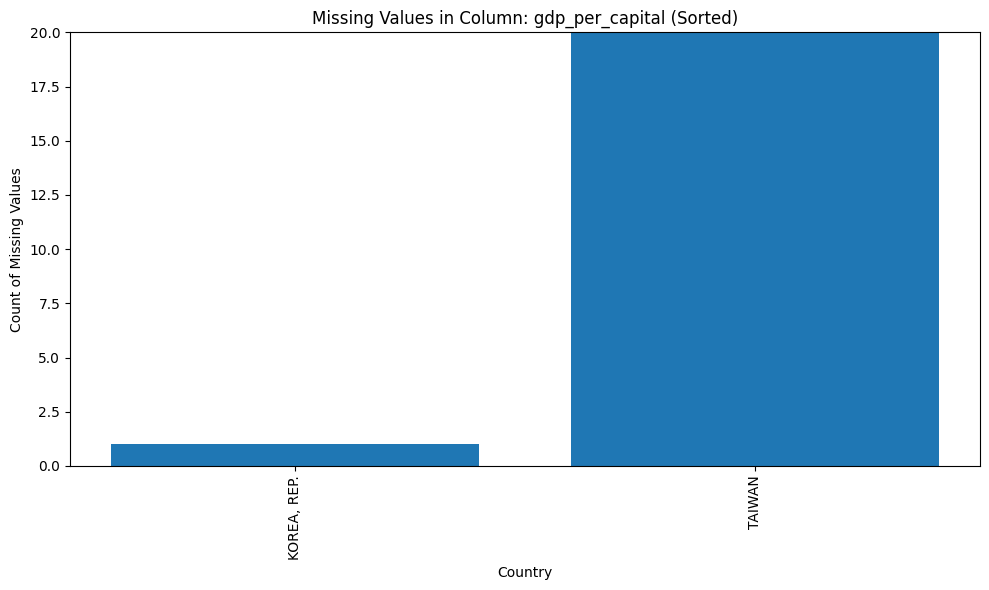

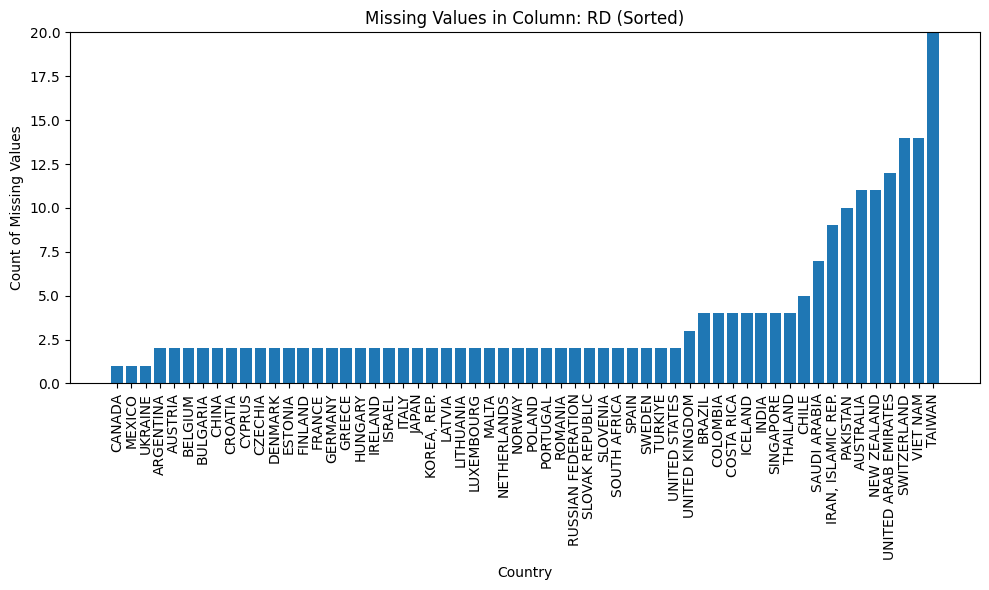

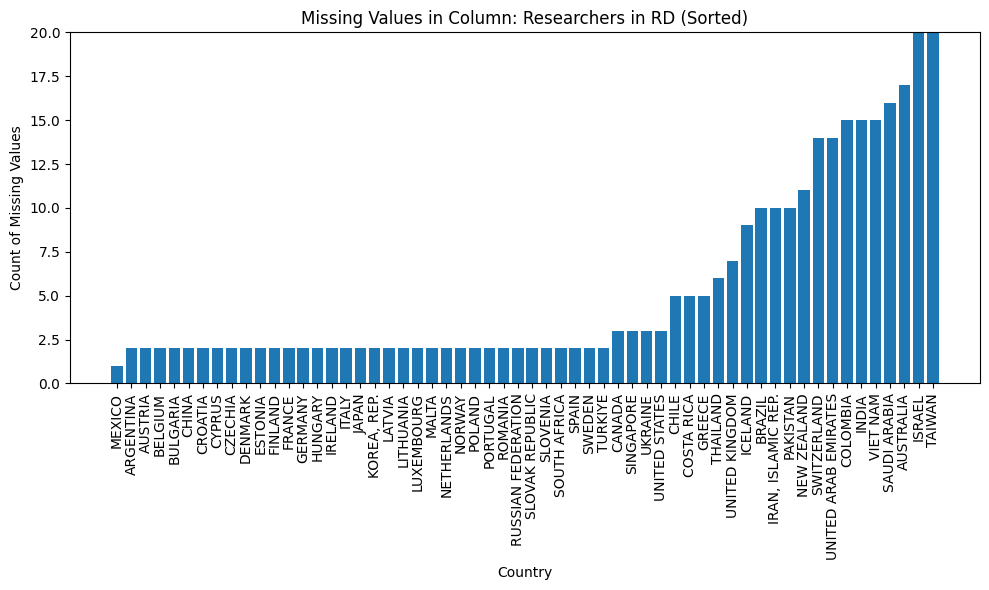

In [2]:
import matplotlib.pyplot as plt
columns_to_check = df.columns[2:]
missing_counts = df.groupby('Country')[columns_to_check].apply(lambda x: x.isnull().sum())
missing_counts = missing_counts[missing_counts.sum(axis=1) > 0]
missing_dict = {
    column: missing_counts[column][missing_counts[column] > 0].to_dict()
    for column in missing_counts.columns
}

# Create bar charts sorted by value for each key in the dictionary
for column, missing_data in missing_dict.items():
    if missing_data:  # Only create plots for columns with missing values
        sorted_data = dict(sorted(missing_data.items(), key=lambda item: item[1]))
        plt.figure(figsize=(10, 6))
        plt.bar(sorted_data.keys(), sorted_data.values())
        plt.title(f'Missing Values in Column: {column} (Sorted)')
        plt.xlabel('Country')
        plt.ylabel('Count of Missing Values')
        plt.xticks(rotation=90)
        plt.ylim(0,20)
        plt.tight_layout()
        plt.show()


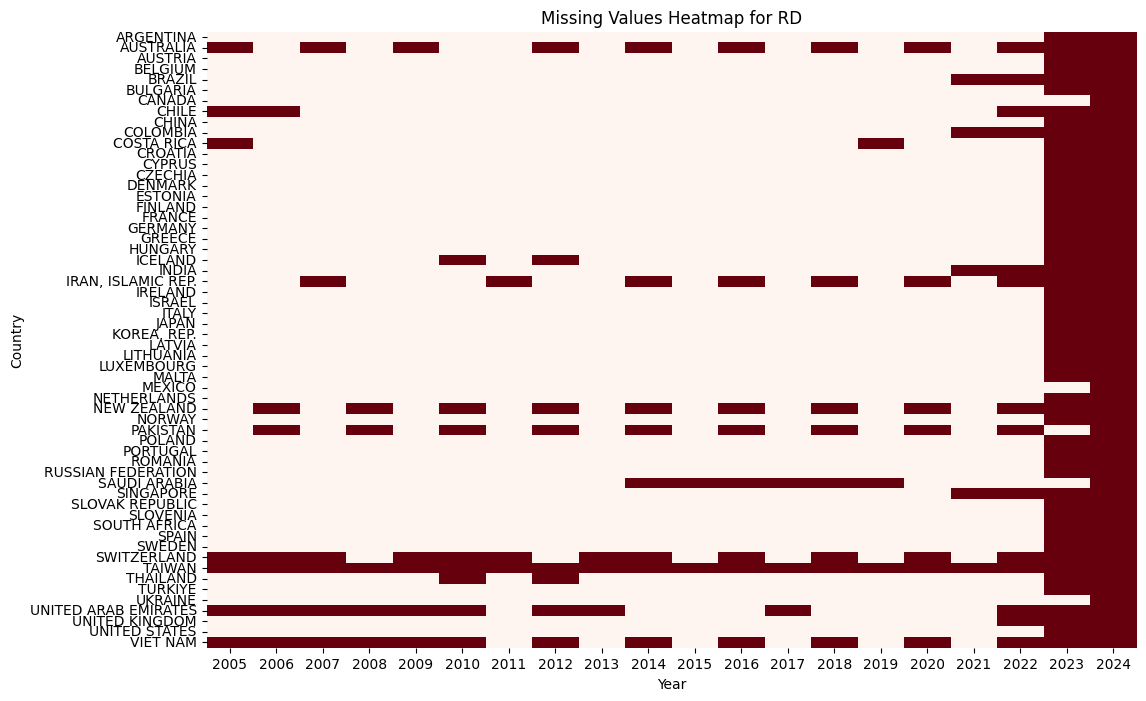

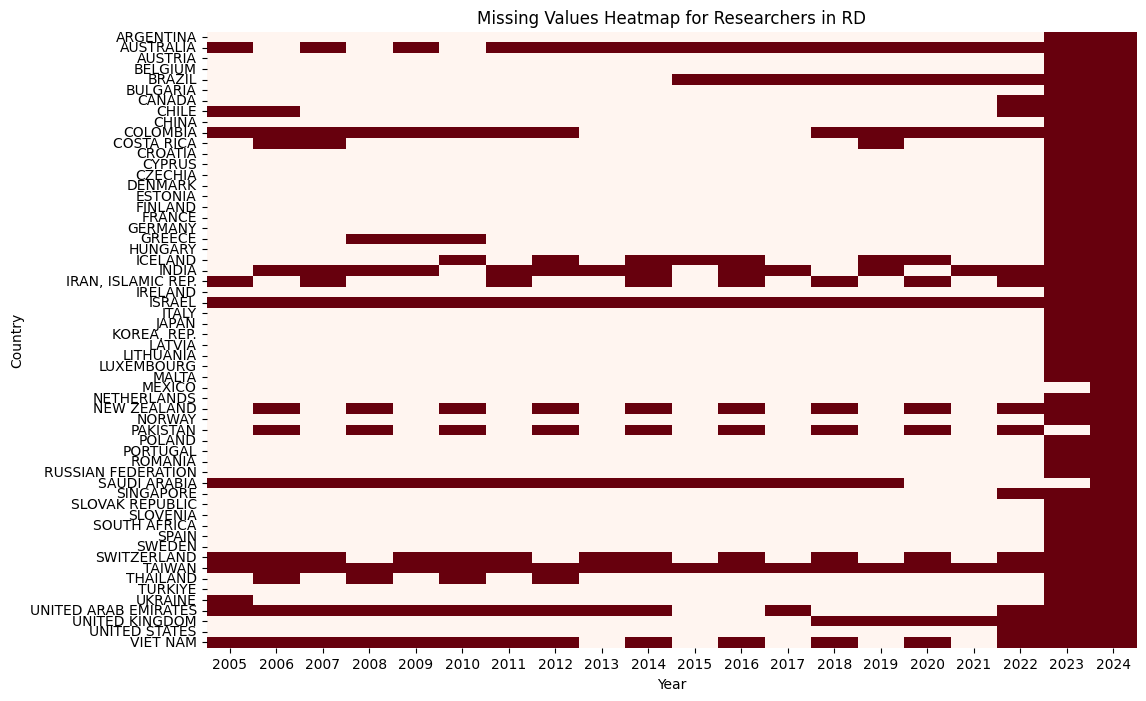

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt
# Extract the last two columns
columns_to_plot = df.columns[-2:]

# Generate heatmaps for the last two columns
for column in columns_to_plot:
    plt.figure(figsize=(12, 8))
    # Pivot the data to create a matrix with 'Country' as rows and 'Year' as columns
    heatmap_data = df.pivot(index='Country', columns='Year', values=column)
    sns.heatmap(heatmap_data.isnull(), cbar=False, cmap='Reds', yticklabels=True)
    plt.title(f"Missing Values Heatmap for {column}")
    plt.xlabel("Year")
    plt.ylabel("Country")
    plt.show()

step2: delete some countries that missing values more than threshold

In [6]:

columns_to_check = ['RD', 'Researchers in RD']
missing_counts = df.groupby('Country')[columns_to_check].apply(lambda x: x.isnull().sum())
countries_to_remove = missing_counts[(missing_counts >= 10).any(axis=1)].index
print(countries_to_remove)
print(len(countries_to_remove))
filtered_df = df[~df['Country'].isin(countries_to_remove)]
filtered_df

Index(['AUSTRALIA', 'BRAZIL', 'COLOMBIA', 'INDIA', 'IRAN, ISLAMIC REP.',
       'ISRAEL', 'NEW ZEALAND', 'PAKISTAN', 'SAUDI ARABIA', 'SWITZERLAND',
       'TAIWAN', 'UNITED ARAB EMIRATES', 'VIET NAM'],
      dtype='object', name='Country')
13


,Country,Year,pub_total,pub_intl,gdp_per_capital,RD,Researchers in RD
0,ARGENTINA,2005,5139,2242,5067.653423,0.42074,816.84120
1,ARGENTINA,2006,5543,2383,5869.380290,0.45216,888.89168
2,ARGENTINA,2007,5947,2596,7185.251551,0.46007,971.29008
3,ARGENTINA,2008,6758,2928,8944.110266,0.47055,1032.67483
4,ARGENTINA,2009,7122,3120,8150.235270,0.58398,1031.64133
...,...,...,...,...,...,...,...
1135,UNITED STATES,2020,504661,219508,64401.507435,3.42467,4464.09495
1136,UNITED STATES,2021,522515,228087,71307.401728,3.48313,4825.18040
1137,UNITED STATES,2022,462747,204386,77860.911291,3.58623,NaN
1138,UNITED STATES,2023,426755,189201,82304.620427,NaN,NaN


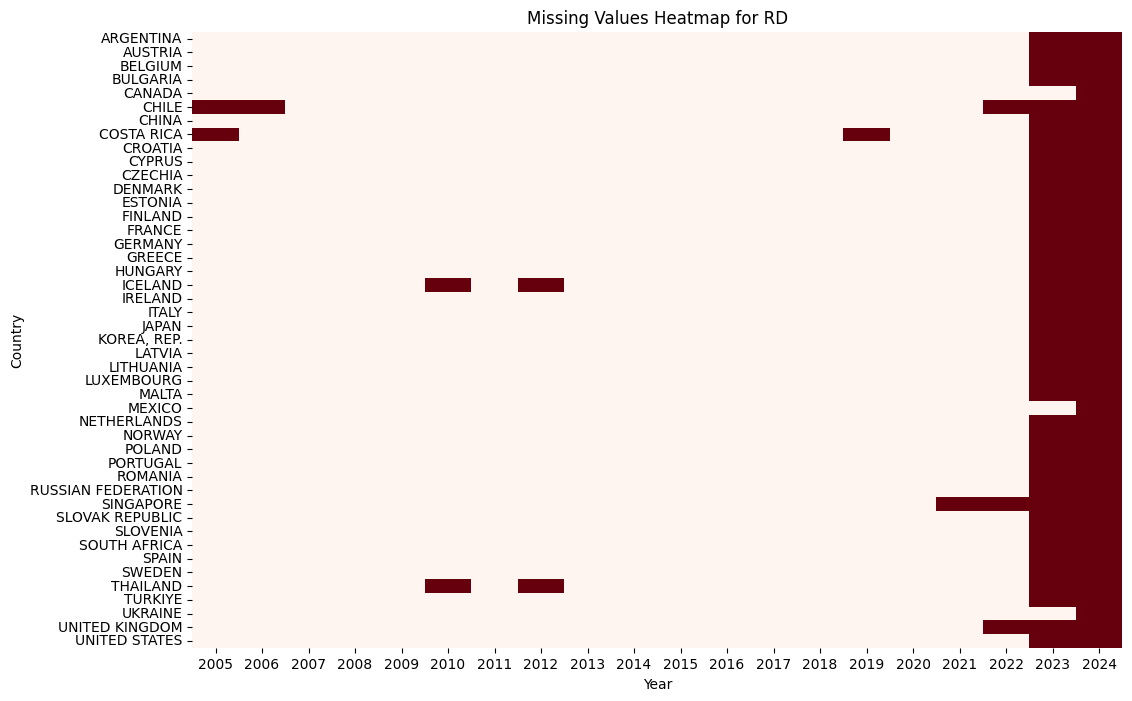

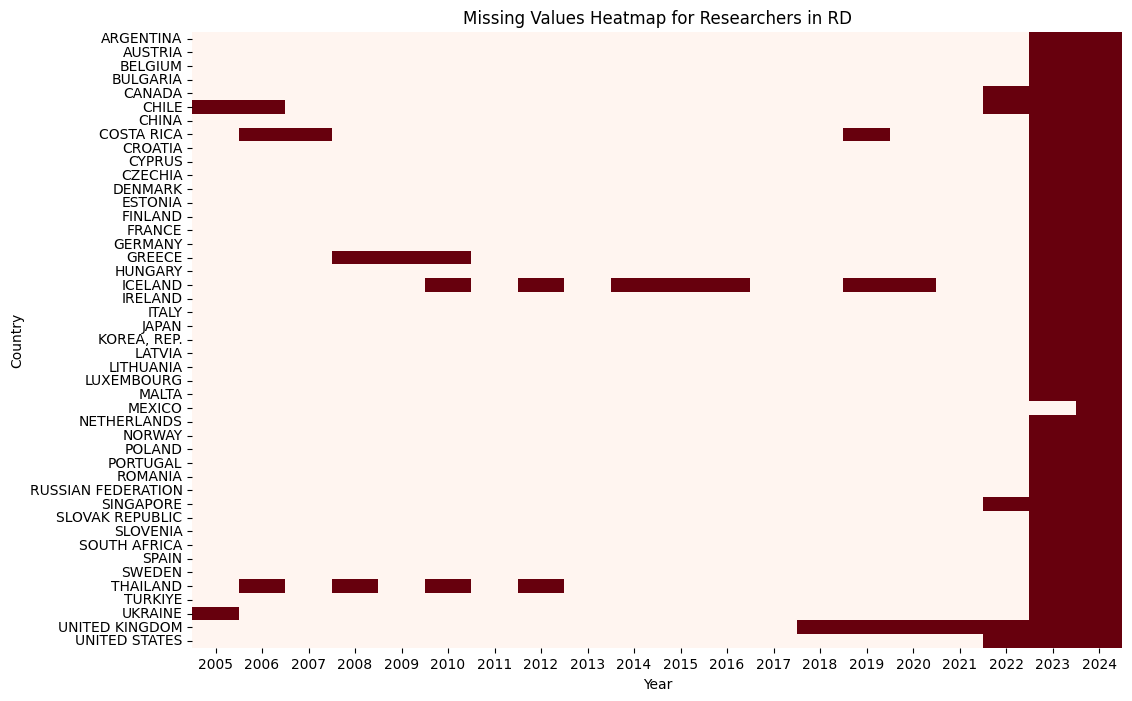

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt
columns_to_plot = filtered_df.columns[-2:]
for column in columns_to_plot:
    plt.figure(figsize=(12, 8))
    # Pivot the data to create a matrix with 'Country' as rows and 'Year' as columns
    heatmap_data = filtered_df.pivot(index='Country', columns='Year', values=column)
    sns.heatmap(heatmap_data.isnull(), cbar=False, cmap='Reds', yticklabels=True)
    plt.title(f"Missing Values Heatmap for {column}")
    plt.xlabel("Year")
    plt.ylabel("Country")
    plt.show()

In [8]:
deleted_dir = "/Users/sunmengge/Dropbox/RUSSIA_UKRAIN_WAR_ALL_CODES/0raw_publiations_process/indicator_clean_data/deleted.xlsx"
filtered_df.to_excel(deleted_dir,index=False)

step3: fill the missing data with the linear pattern

In [9]:
import pandas as pd
import os
filtered_df = pd.read_excel("/Users/sunmengge/Dropbox/RUSSIA_UKRAIN_WAR_ALL_CODES/0raw_publiations_process/indicator_clean_data/deleted.xlsx")
filtered_df

,Country,Year,pub_total,pub_intl,gdp_per_capital,RD,Researchers in RD
0,ARGENTINA,2005,5139,2242,5067.653423,0.42074,816.84120
1,ARGENTINA,2006,5543,2383,5869.380290,0.45216,888.89168
2,ARGENTINA,2007,5947,2596,7185.251551,0.46007,971.29008
3,ARGENTINA,2008,6758,2928,8944.110266,0.47055,1032.67483
4,ARGENTINA,2009,7122,3120,8150.235270,0.58398,1031.64133
...,...,...,...,...,...,...,...
895,UNITED STATES,2020,504661,219508,64401.507435,3.42467,4464.09495
896,UNITED STATES,2021,522515,228087,71307.401728,3.48313,4825.18040
897,UNITED STATES,2022,462747,204386,77860.911291,3.58623,NaN
898,UNITED STATES,2023,426755,189201,82304.620427,NaN,NaN


in terms of RD Column

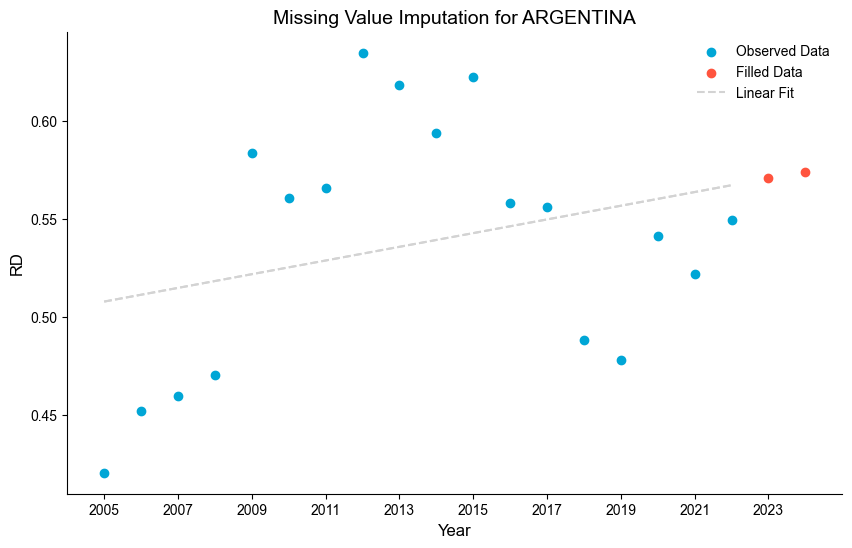

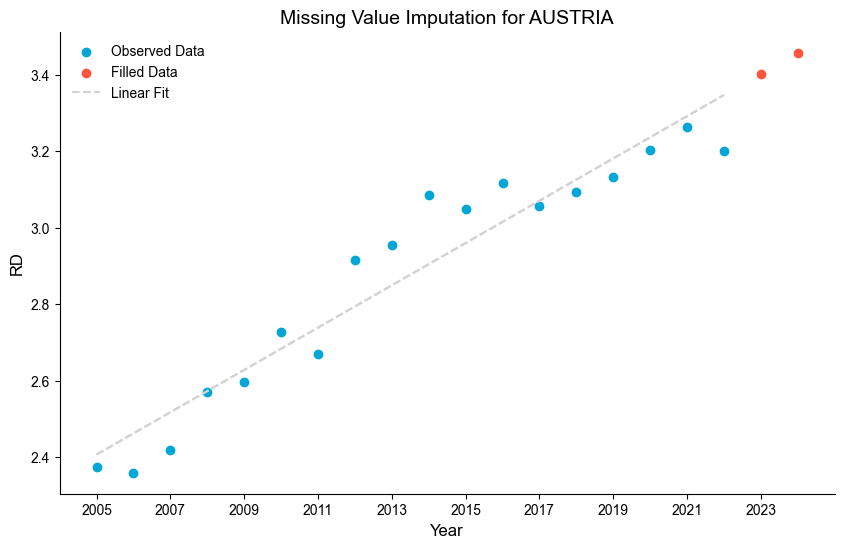

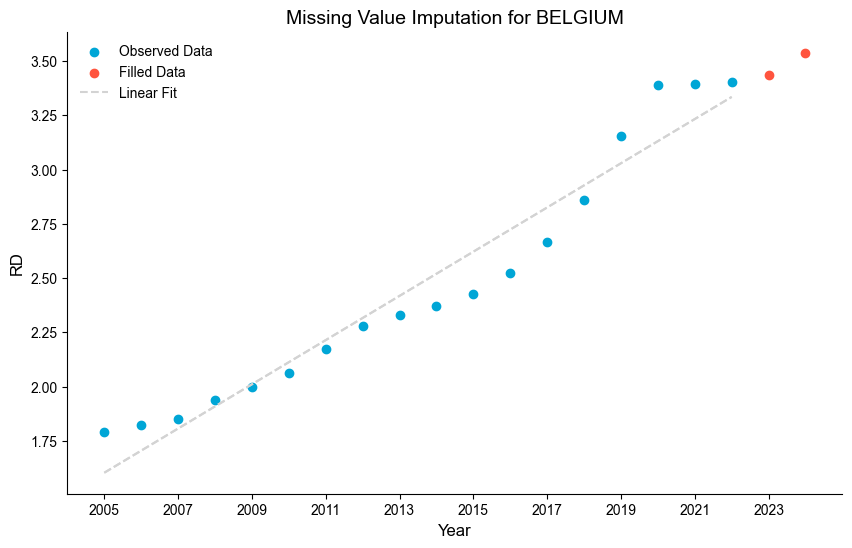

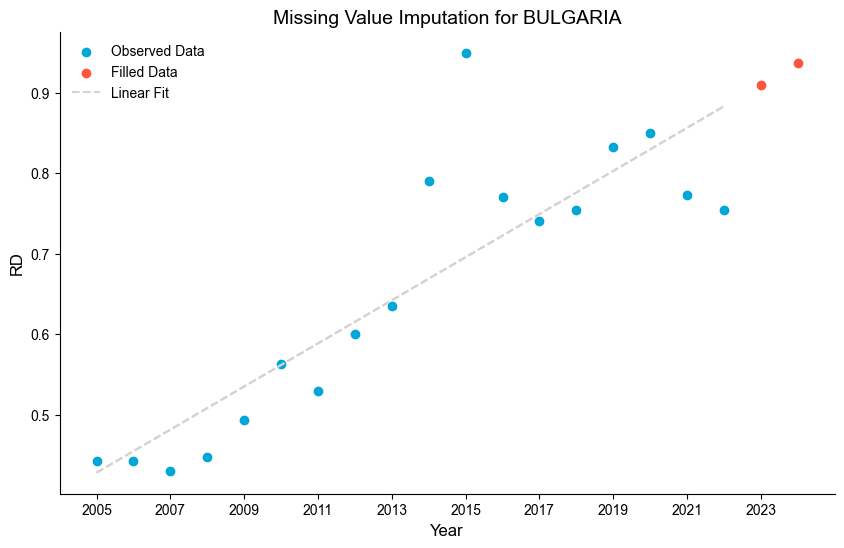

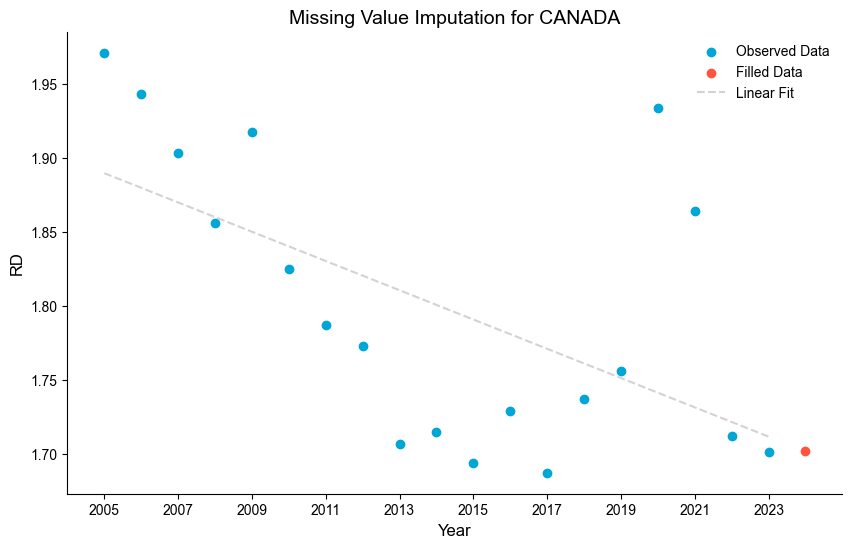

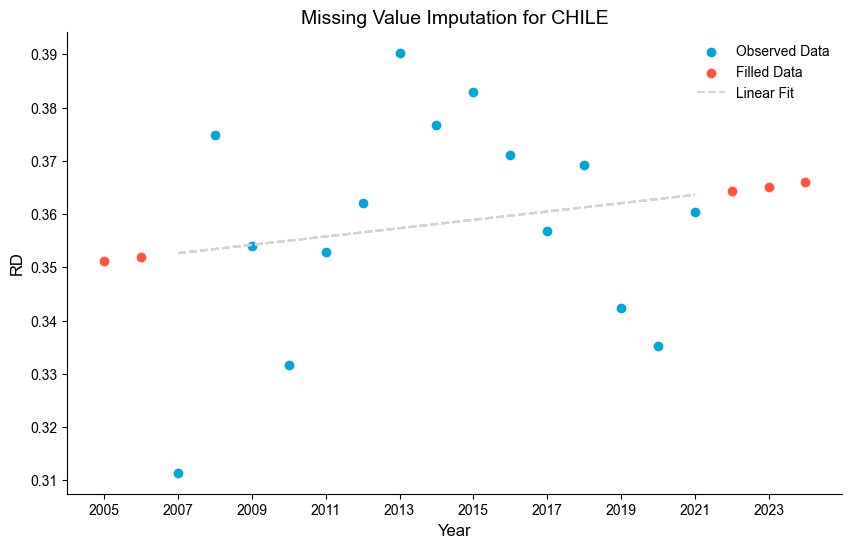

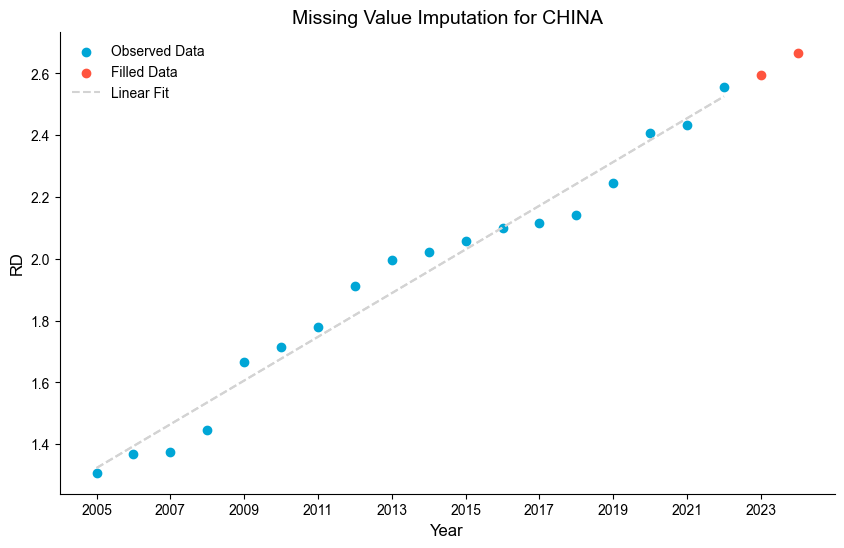

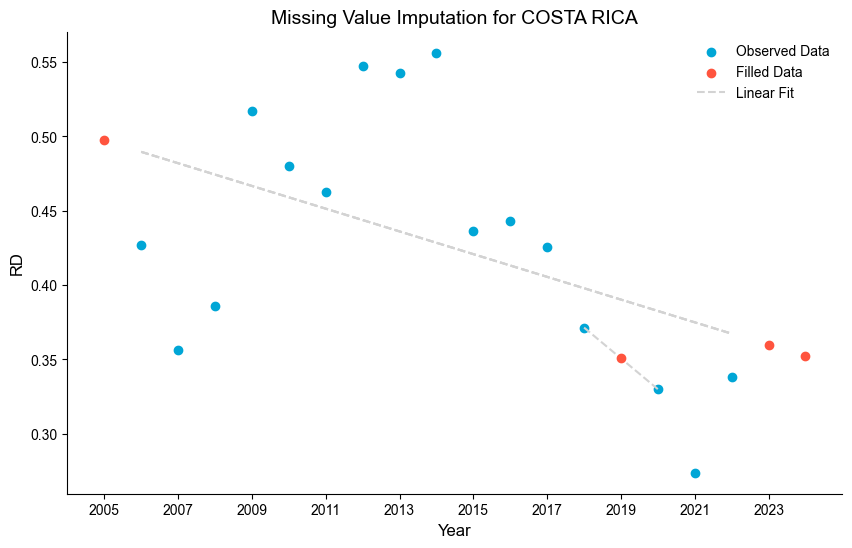

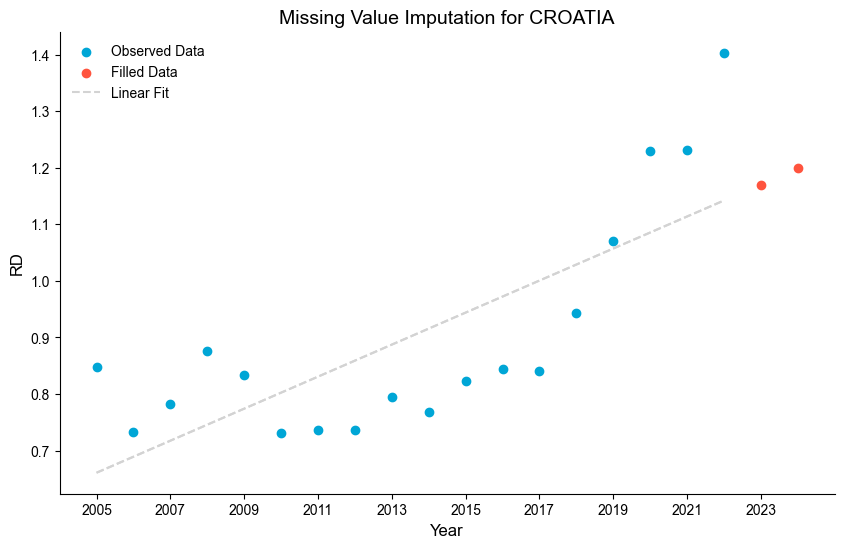

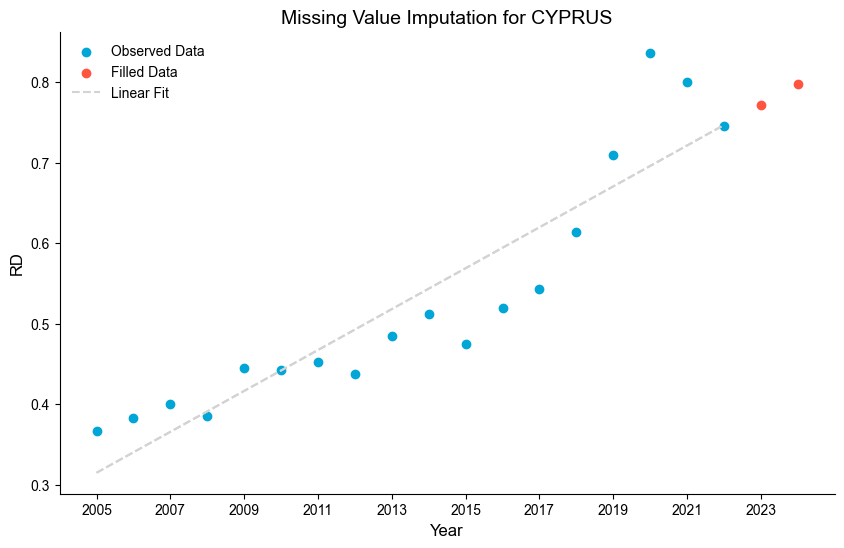

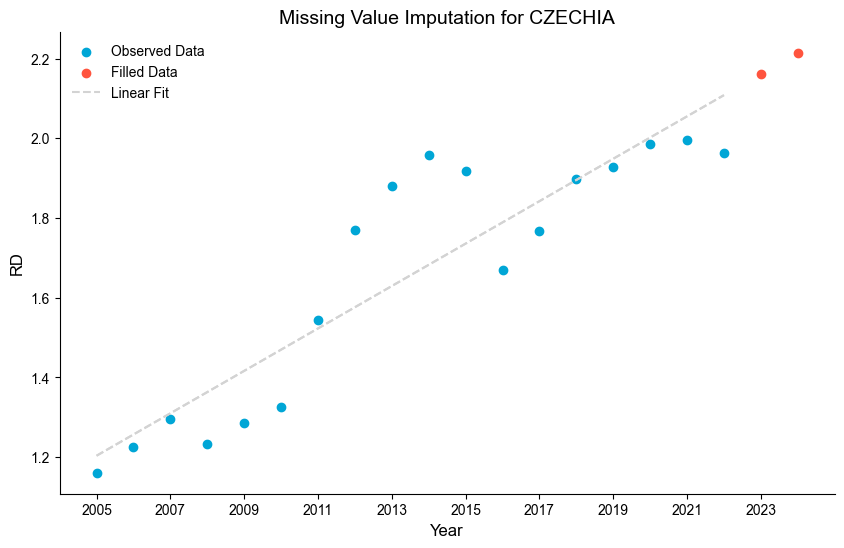

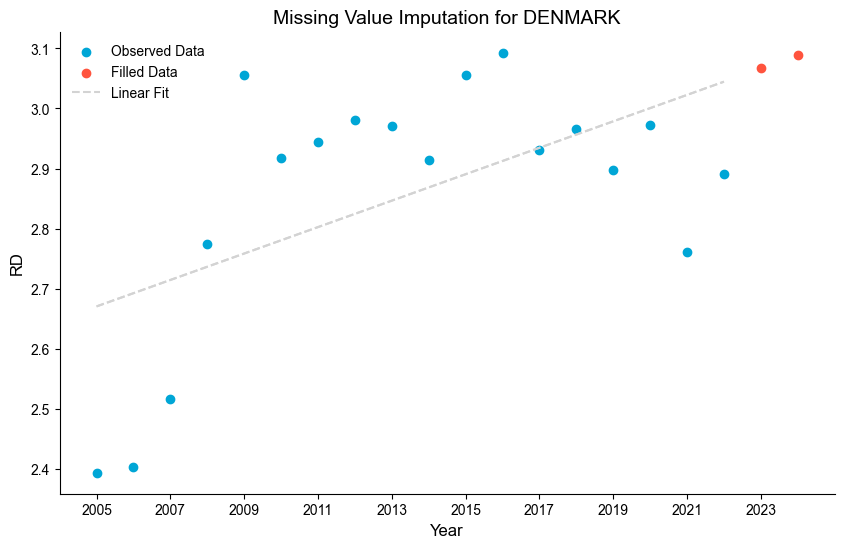

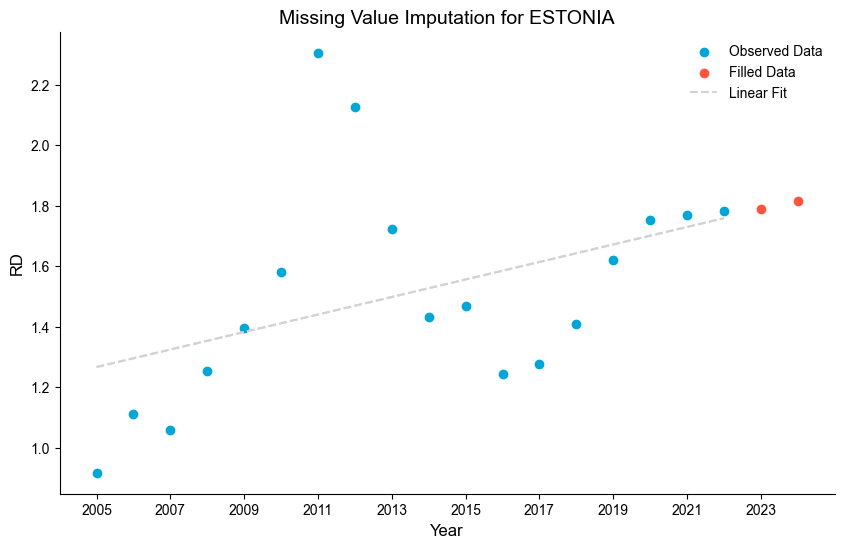

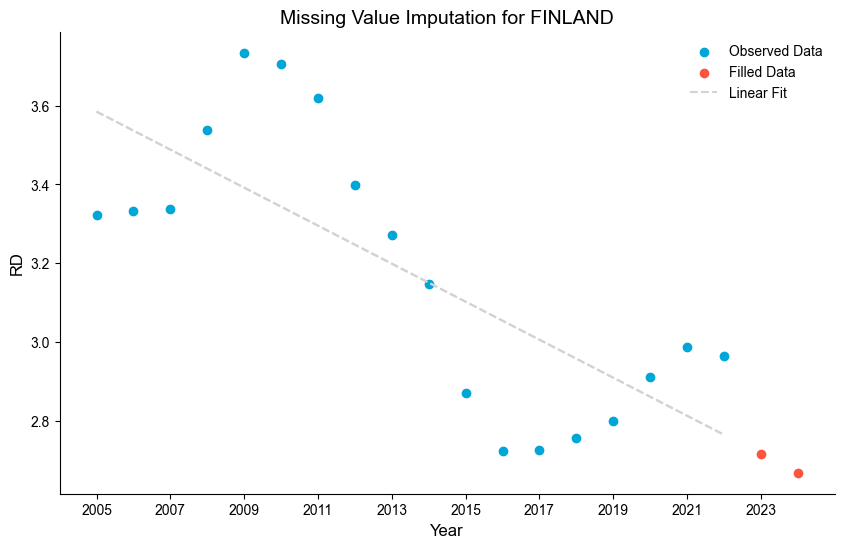

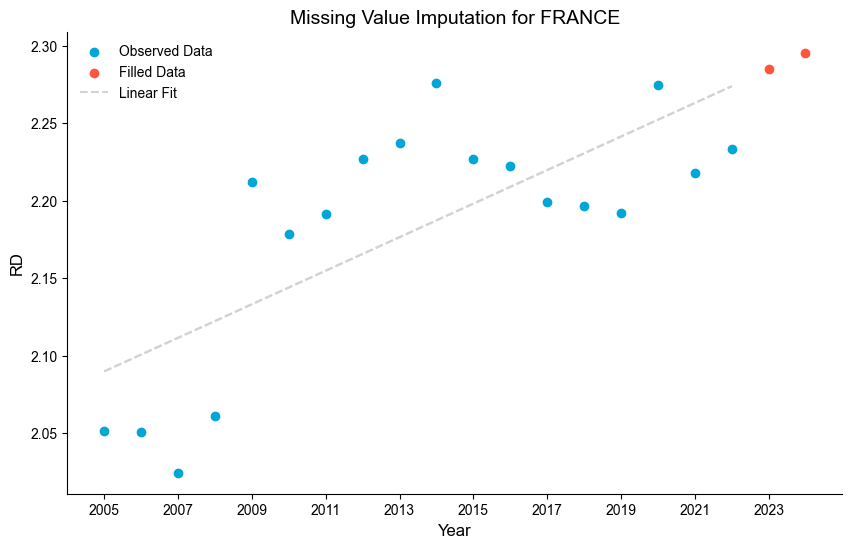

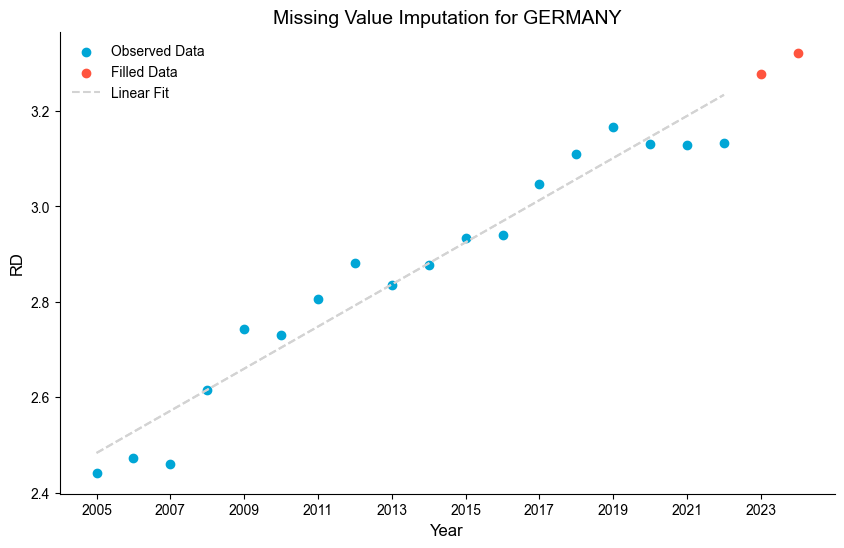

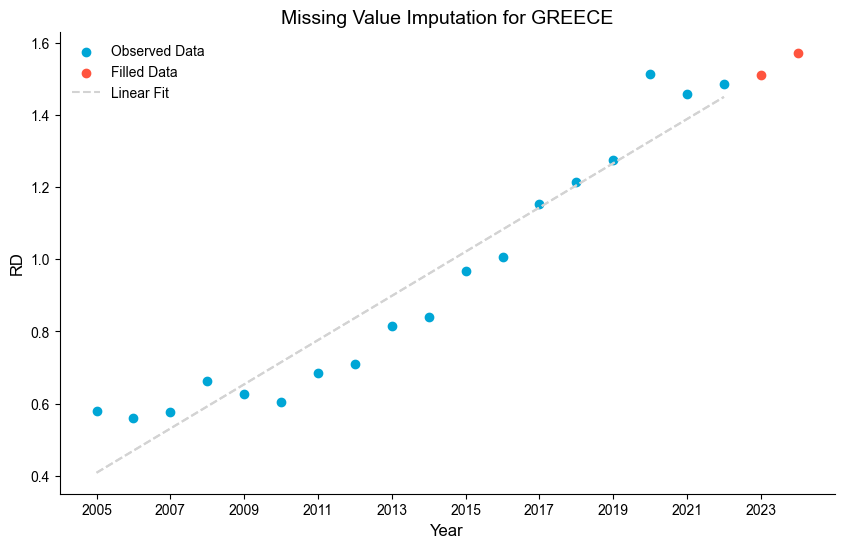

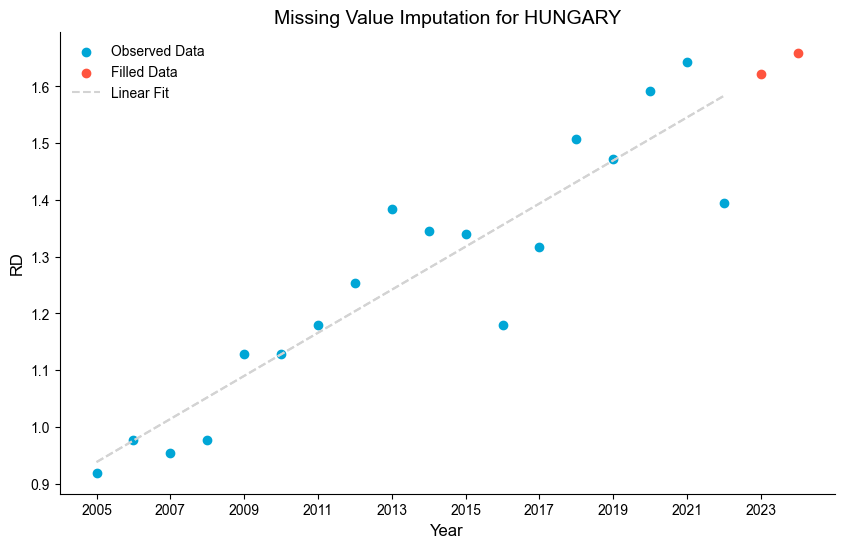

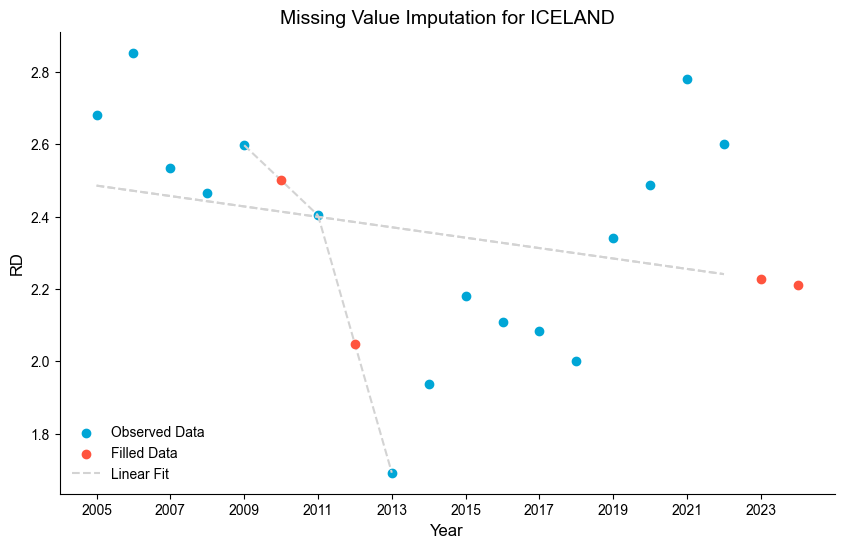

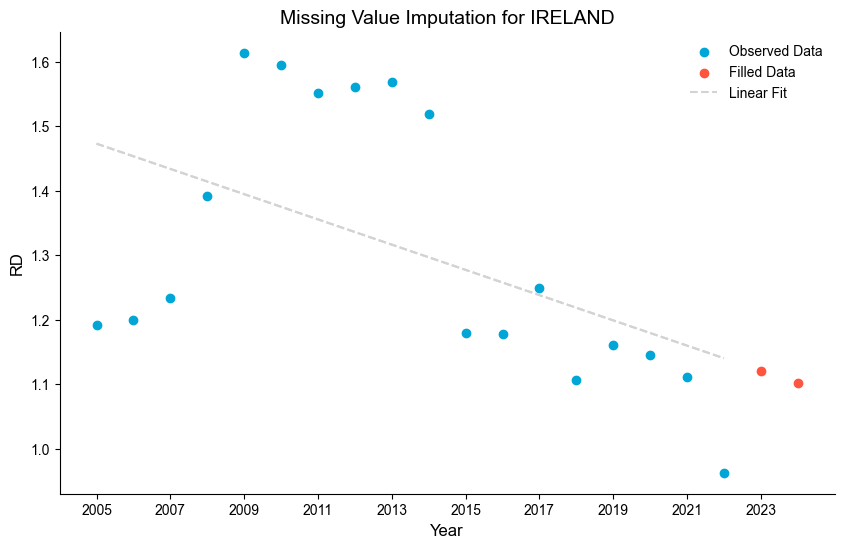

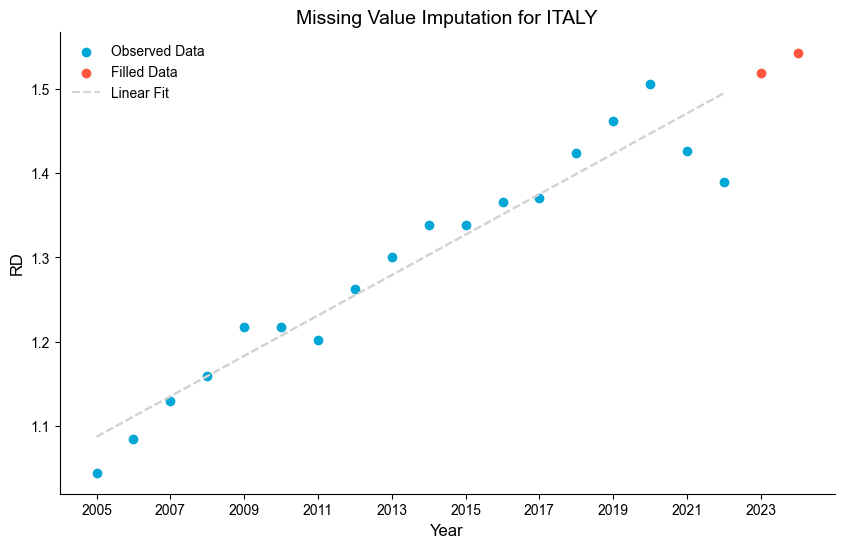

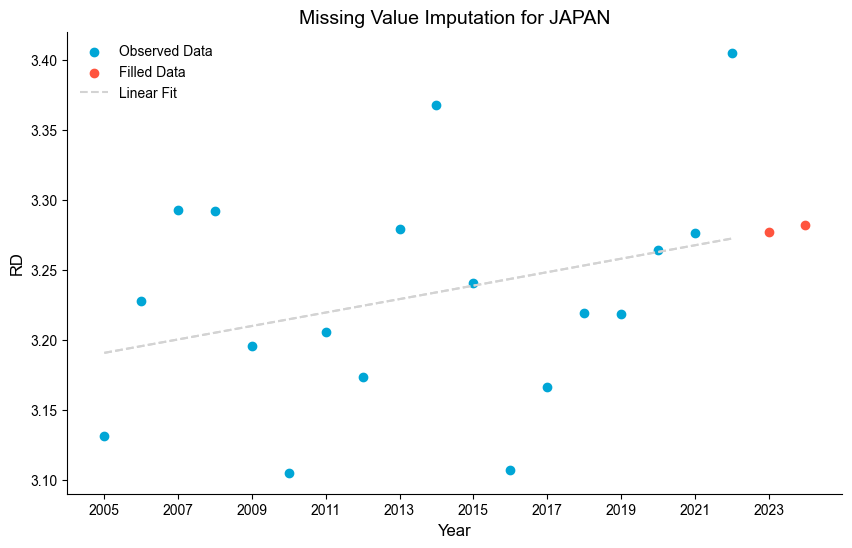

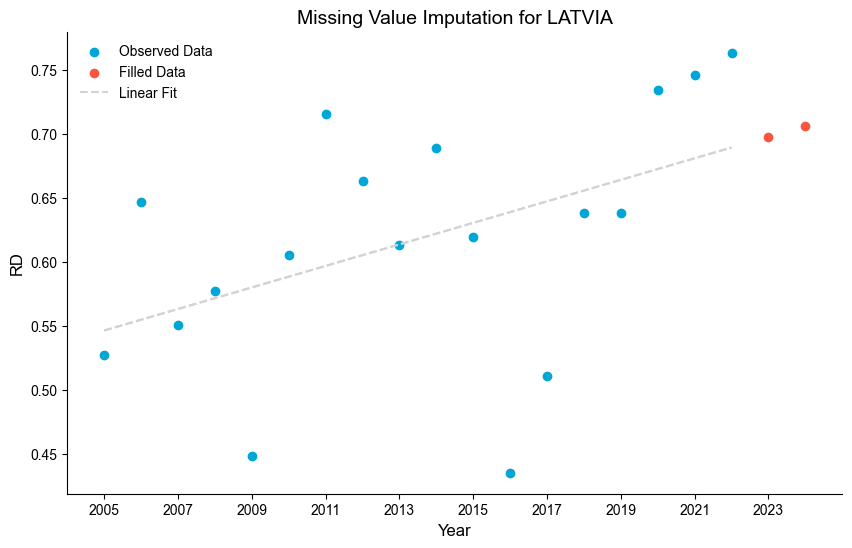

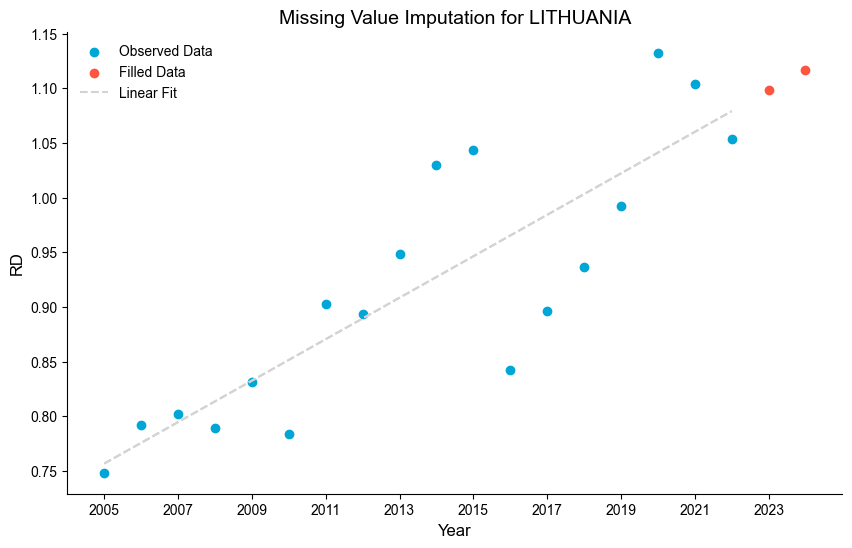

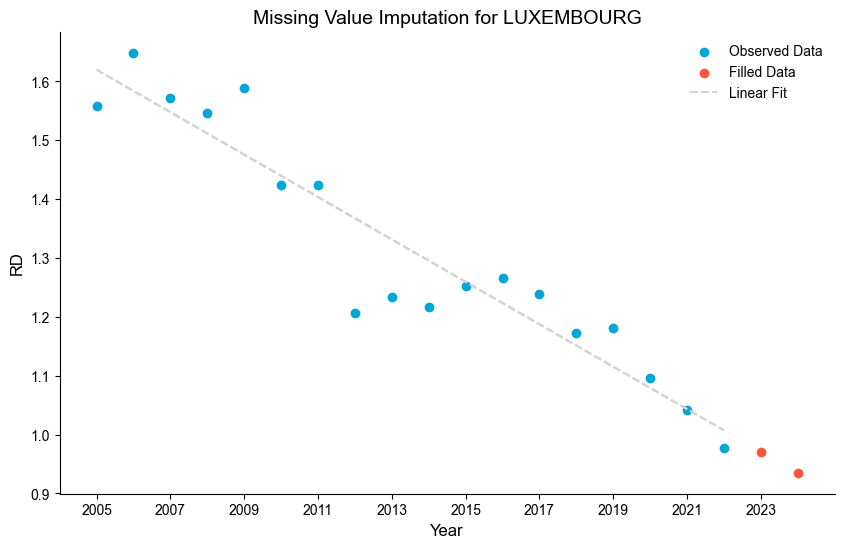

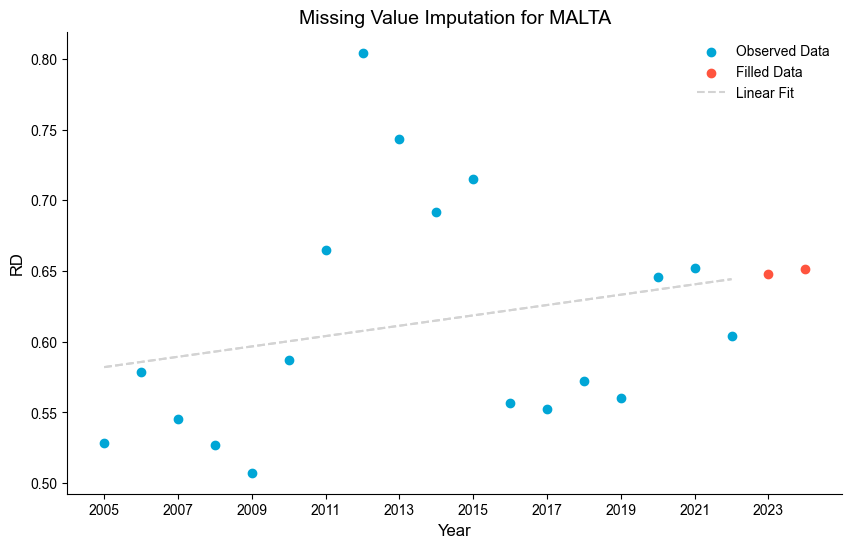

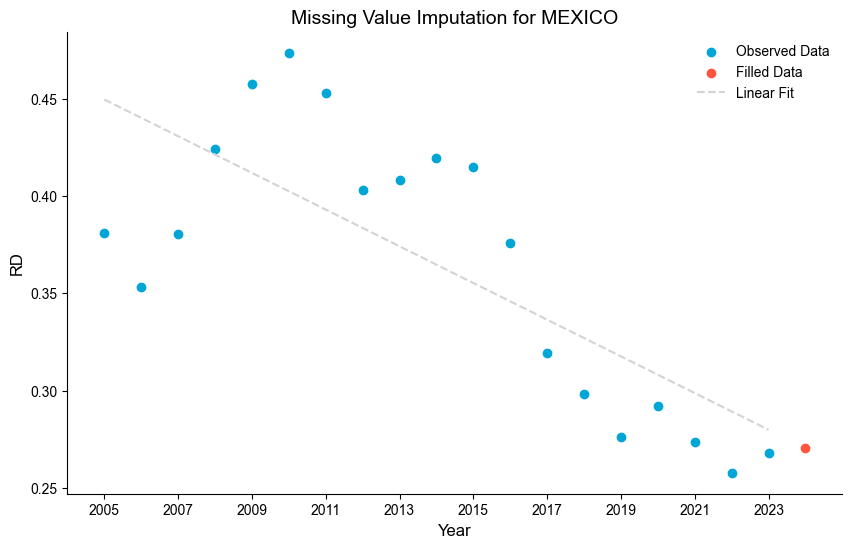

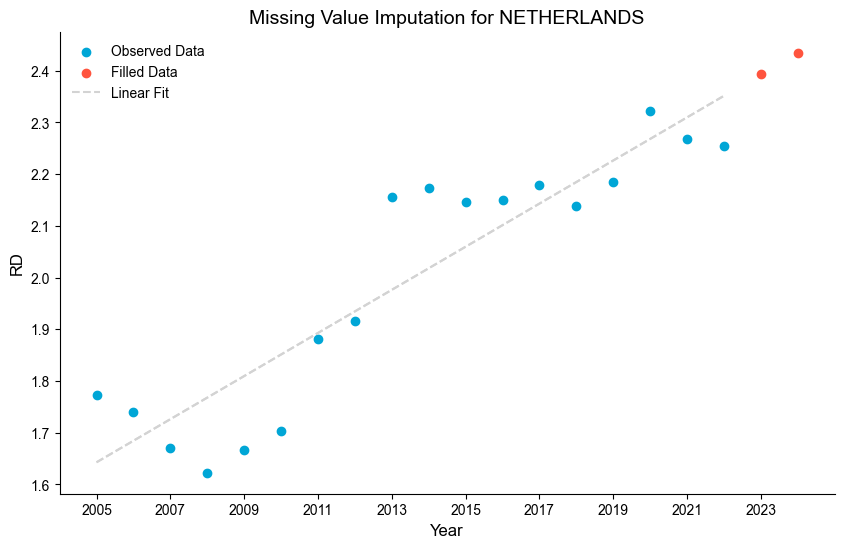

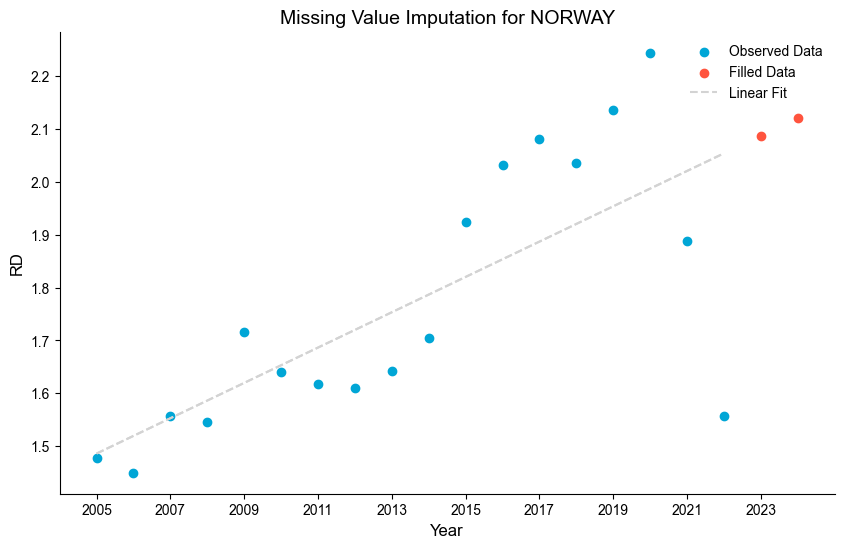

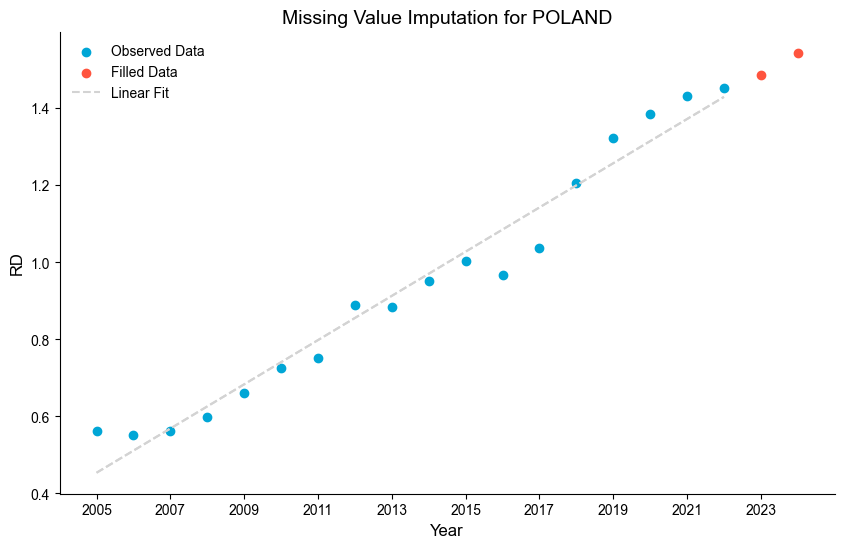

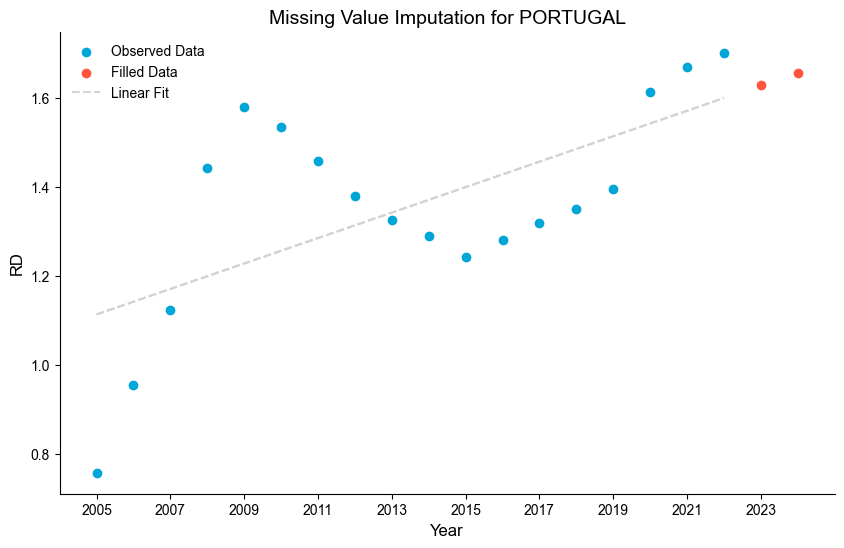

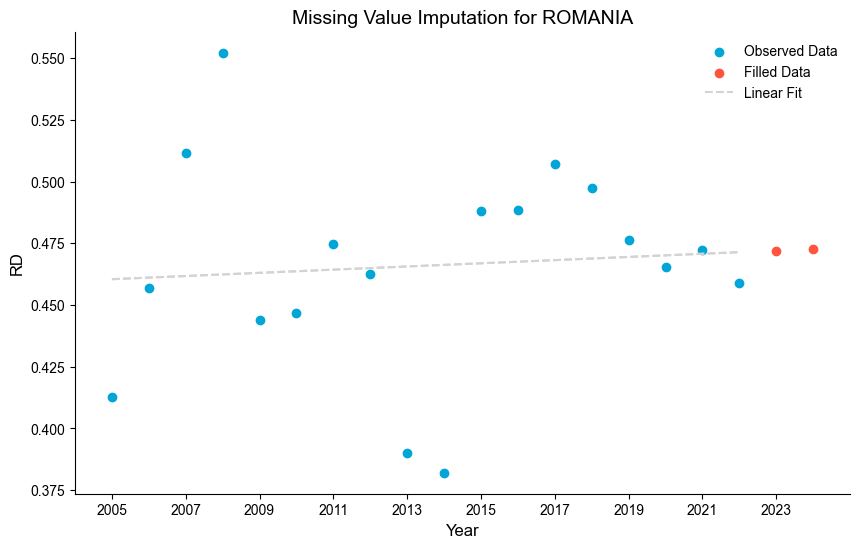

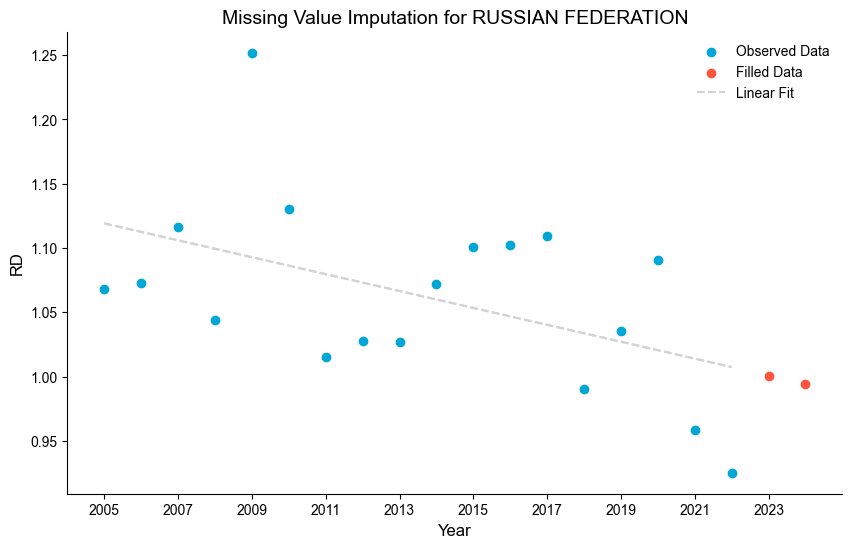

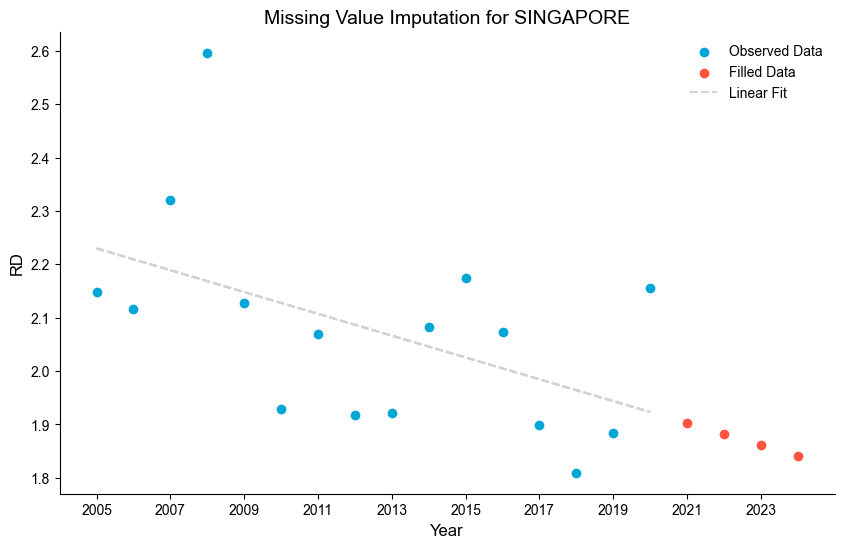

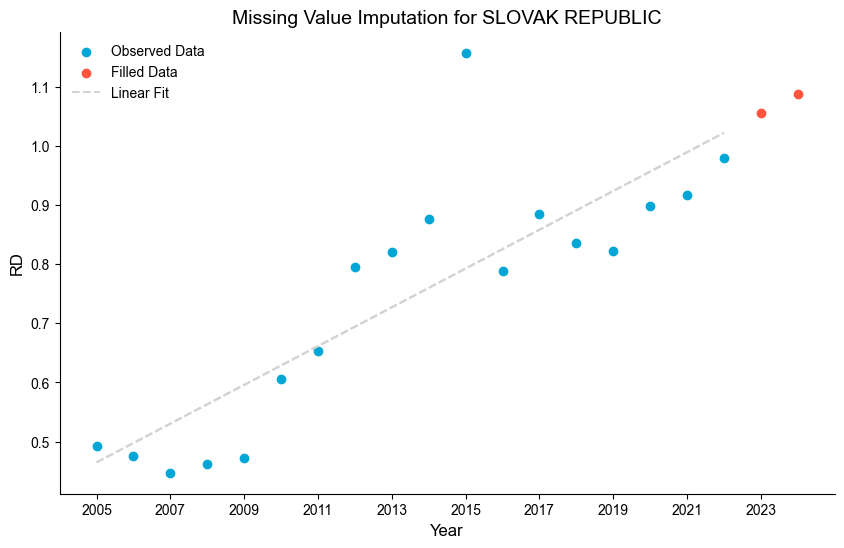

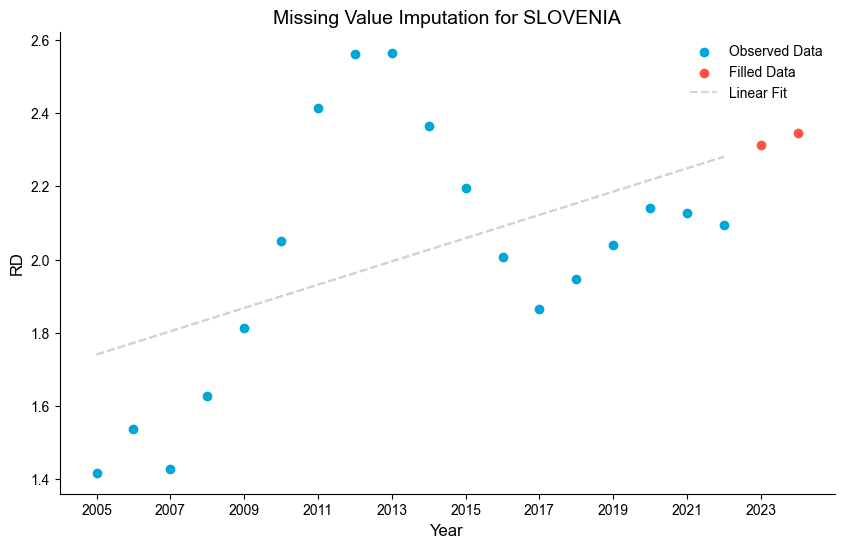

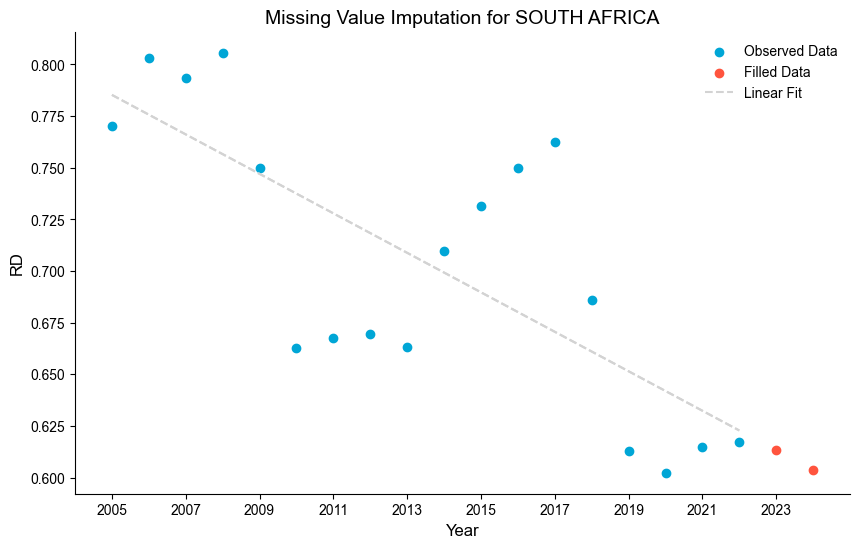

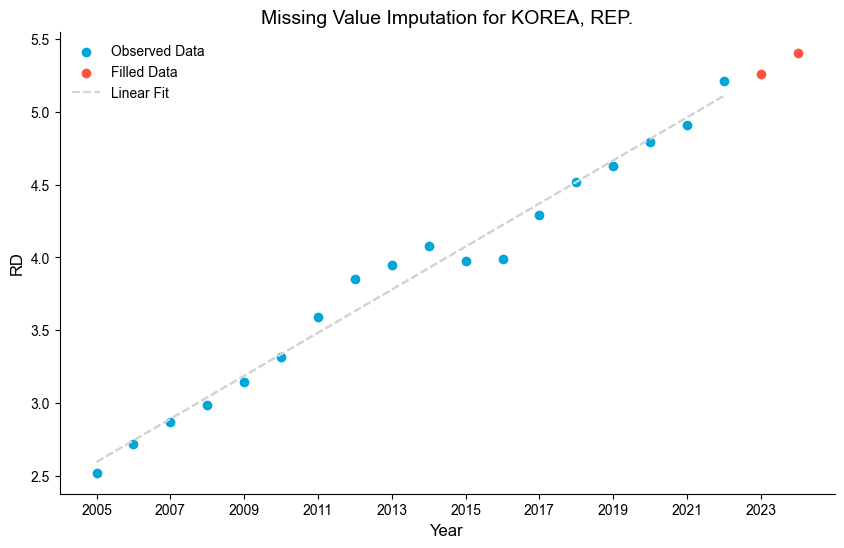

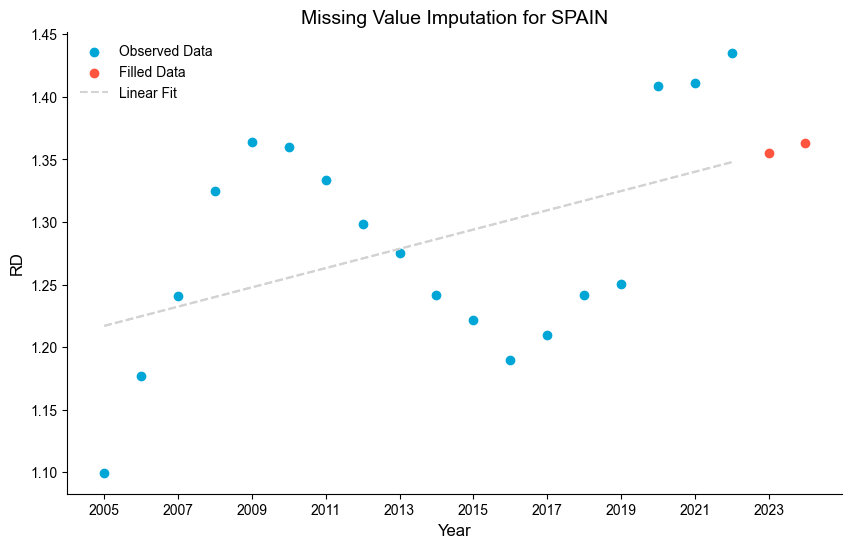

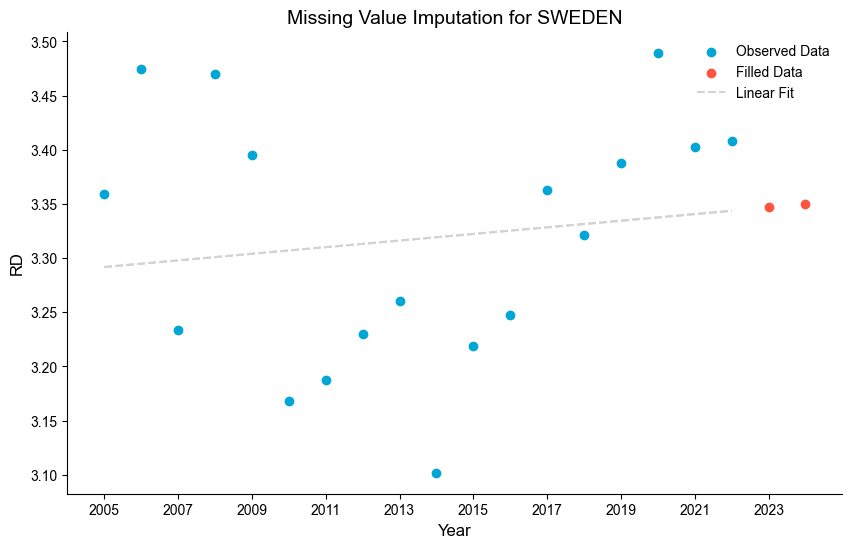

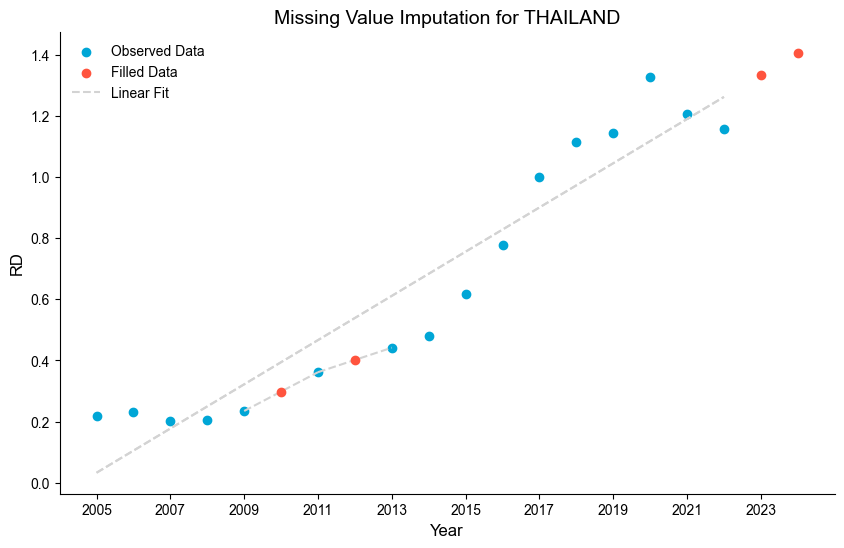

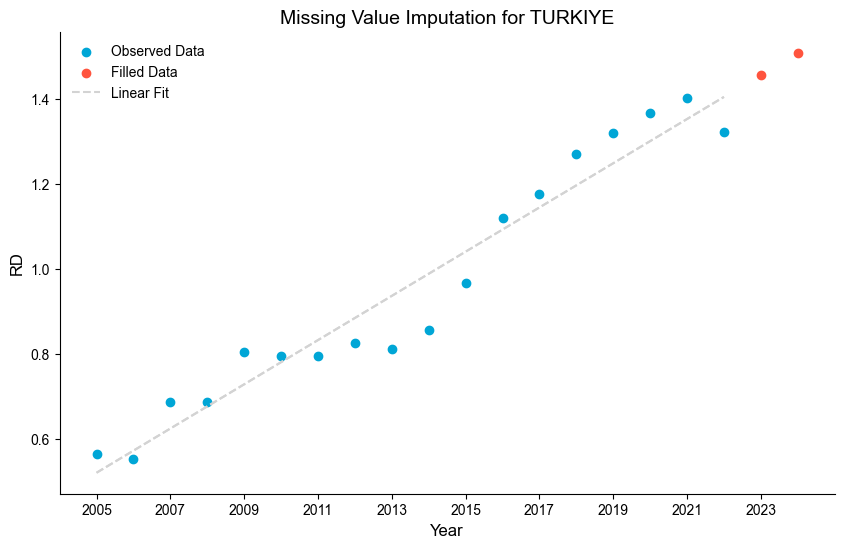

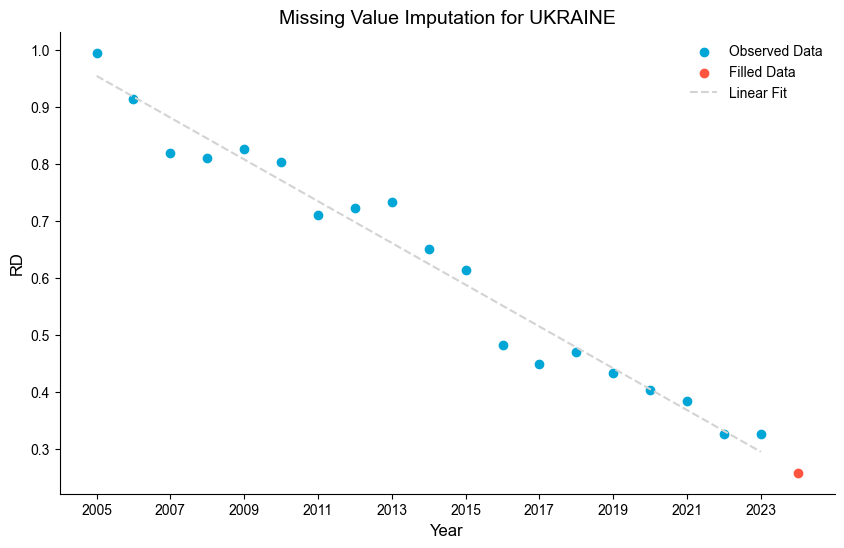

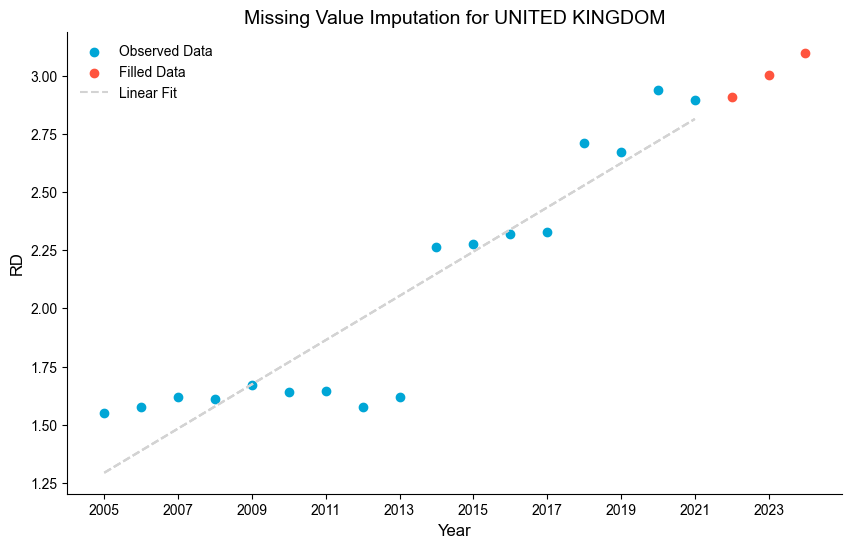

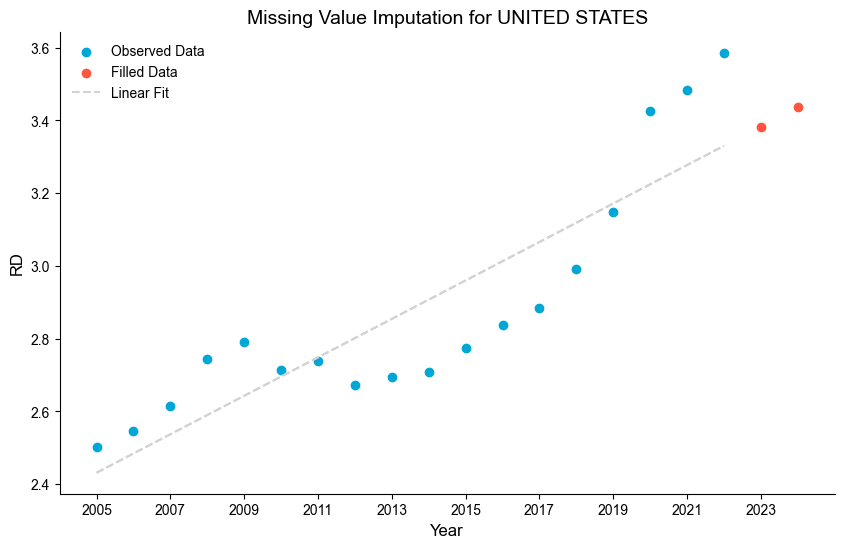

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandas as pd

def analyze_and_fill_missing_values(df, column):
    filled_dfs = []
    
    for country in df['Country'].unique():
        country_data = df[df['Country'] == country].copy()
        non_null_data = country_data.dropna(subset=[column])
        
        # Get known data points
        years = non_null_data['Year'].values
        values = non_null_data[column].values
        
        # Get years with missing values
        missing_years = country_data[country_data[column].isnull()]['Year'].values
        
        def fit_missing_value(target_year, train_years, train_values):
            """
            Choose appropriate filling method based on target year position
            """
            # Ensure data is sorted by year
            sort_idx = np.argsort(train_years)
            train_years = train_years[sort_idx]
            train_values = train_values[sort_idx]
            
            # For missing values in the middle, use linear interpolation
            if target_year > train_years[0] and target_year < train_years[-1]:
                # Find nearest observation points before and after target year
                after_idx = np.searchsorted(train_years, target_year)
                before_idx = after_idx - 1
                
                # Use only adjacent points for linear interpolation
                x = [train_years[before_idx], train_years[after_idx]]
                y = [train_values[before_idx], train_values[after_idx]]
                
            # For missing values at ends, use all points for linear extrapolation
            else:
                x = train_years
                y = train_values
            
            # Linear fitting
            coeffs = np.polyfit(x, y, 1)
            linear = np.poly1d(coeffs)
            
            return linear(target_year), linear, x
        
        # Store filled values and fitting info for plotting
        filled_values = []
        fit_info = []
        
        # Fill missing values
        if len(missing_years) > 0:
            for year in missing_years:
                filled_value, linear_func, fit_range = fit_missing_value(year, years, values)
                country_data.loc[country_data['Year'] == year, column] = filled_value
                filled_values.append((year, filled_value))
                fit_info.append({
                    'year': year,
                    'func': linear_func,
                    'range': fit_range
                })
            
            # Plot fitting results
            from matplotlib.ticker import MaxNLocator
            import matplotlib as mpl
            mpl.rcParams['font.family'] = 'sans-serif'
            mpl.rcParams['font.sans-serif'] = ['Arial']

            plt.figure(figsize=(10, 6))
            ax = plt.gca()

            # Axis spines: keep bottom/left light gray; hide top/right
            # for spine in ['bottom', 'left']:
            #     ax.spines[spine].set_color('#d3d3d3')
            for spine in ['top', 'right']:
                ax.spines[spine].set_visible(False)

            # Plot original data points (observed)
            plt.scatter(years, values, color='#00a6d6', label='Observed Data')

            # Plot filled data points
            filled_years, filled_vals = zip(*filled_values)
            plt.scatter(filled_years, filled_vals, color='#ff543e', label='Filled Data', zorder=5)

            # Plot fitting lines in light gray
            for info in fit_info:
                x_fit = np.linspace(min(info['range']), max(info['range']), 100)
                y_fit = info['func'](x_fit)
                plt.plot(
                    x_fit, y_fit, '--', color='#d3d3d3', linewidth=1.5,
                    label='Linear Fit' if 'Linear Fit' not in plt.gca().get_legend_handles_labels()[1] else ''
                )

            plt.title(f'Missing Value Imputation for {country}', fontsize=14)
            plt.xlabel('Year', fontsize=12)
            plt.ylabel(column, fontsize=12)

            # Force x-axis ticks: 2005-2024 every 2 years, integer labels
            from matplotlib.ticker import FixedLocator
            ax.set_xlim(2004, 2025)
            ax.xaxis.set_major_locator(FixedLocator(list(range(2005, 2024, 2))))

            # Legend without frame
            plt.legend(frameon=False)

            # Remove background gridlines
            plt.grid(False)
            plt.show()
        
        filled_dfs.append(country_data)
    
    return pd.concat(filled_dfs, ignore_index=True)

# Use modified function for data imputation
fitting_df_RD = analyze_and_fill_missing_values(filtered_df, 'RD')

In [21]:
completed_dir1 = "/Users/sunmengge/Dropbox/RUSSIA_UKRAIN_WAR_ALL_CODES/0raw_publiations_process/indicator_clean_data/completed1.xlsx"
fitting_df_RD.to_excel(completed_dir1,index = False)
fitting_df_RD

,Country,Year,pub_total,pub_intl,gdp_per_capital,RD,Researchers in RD
0,ARGENTINA,2005,5139,2242,5067.653423,0.420740,816.84120
1,ARGENTINA,2006,5543,2383,5869.380290,0.452160,888.89168
2,ARGENTINA,2007,5947,2596,7185.251551,0.460070,971.29008
3,ARGENTINA,2008,6758,2928,8944.110266,0.470550,1032.67483
4,ARGENTINA,2009,7122,3120,8150.235270,0.583980,1031.64133
...,...,...,...,...,...,...,...
895,UNITED STATES,2020,504661,219508,64401.507435,3.424670,4464.09495
896,UNITED STATES,2021,522515,228087,71307.401728,3.483130,4825.18040
897,UNITED STATES,2022,462747,204386,77860.911291,3.586230,NaN
898,UNITED STATES,2023,426755,189201,82304.620427,3.383009,NaN


in terms of researchers in rd

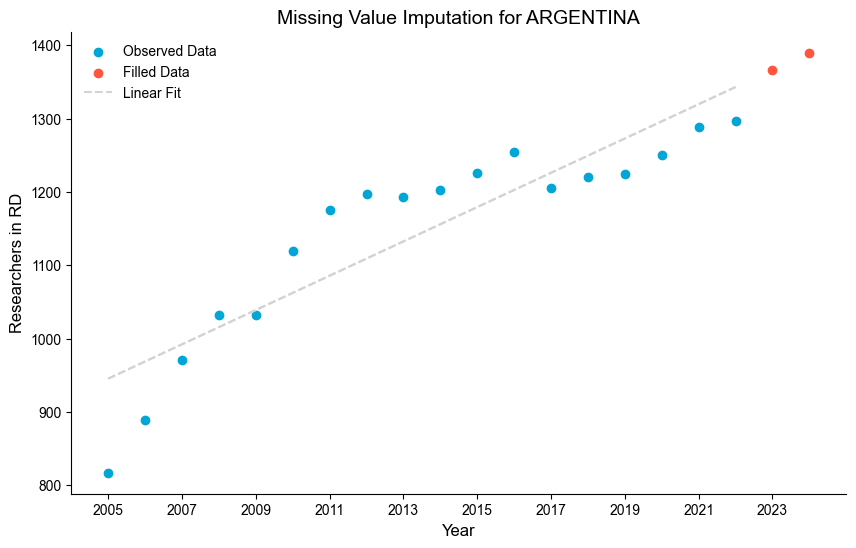

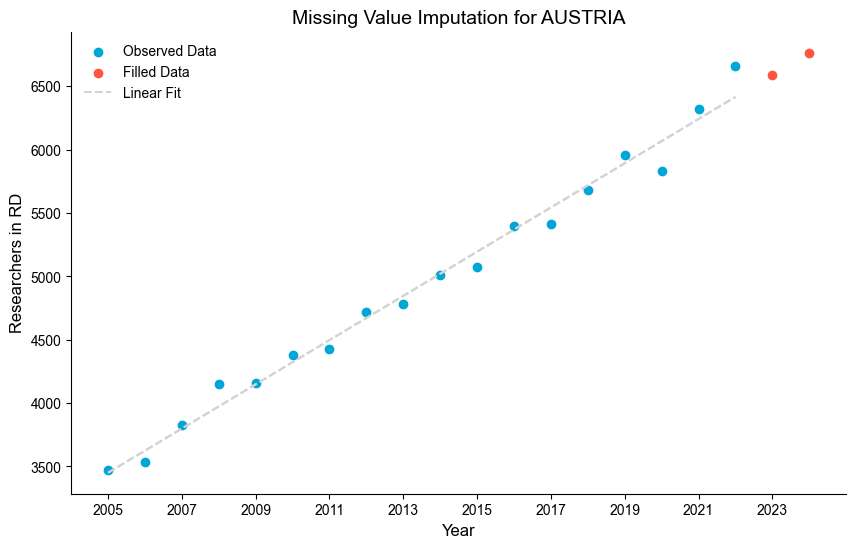

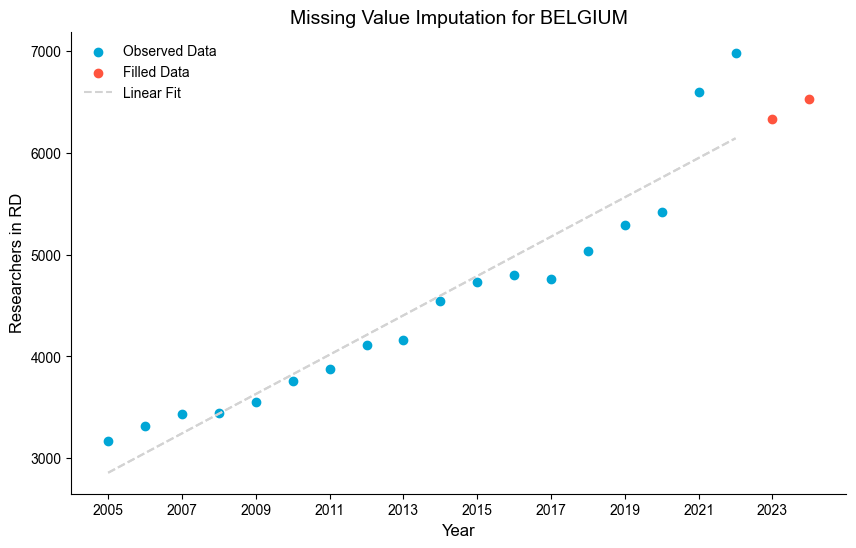

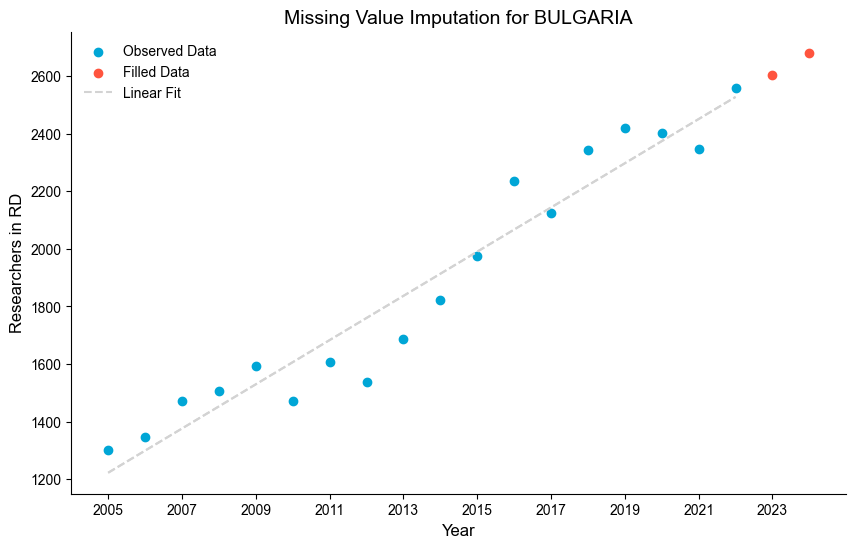

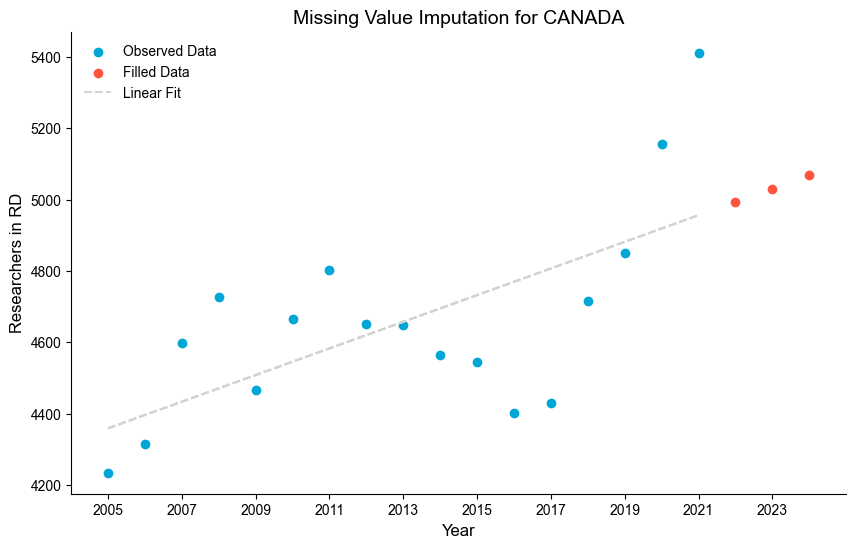

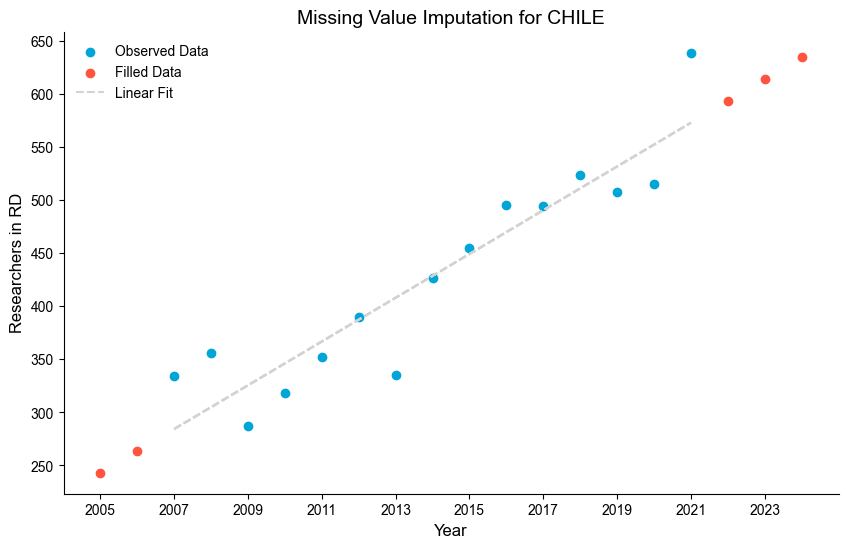

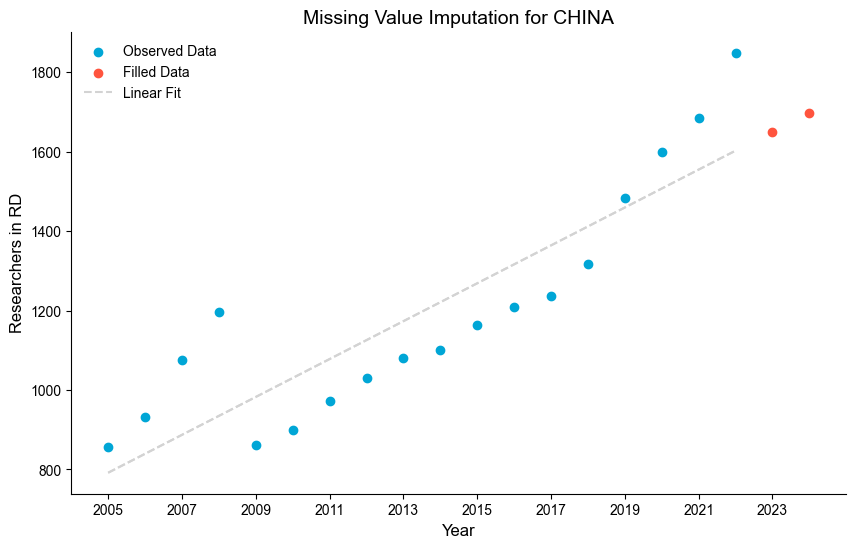

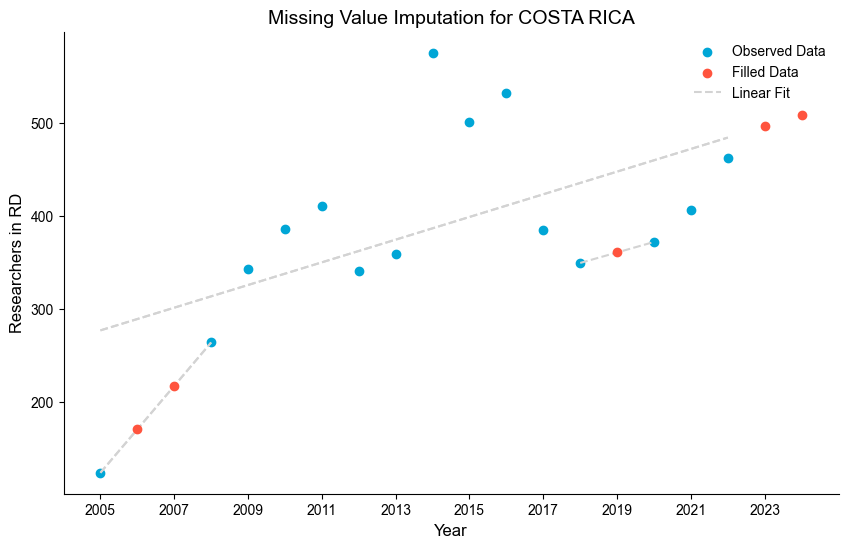

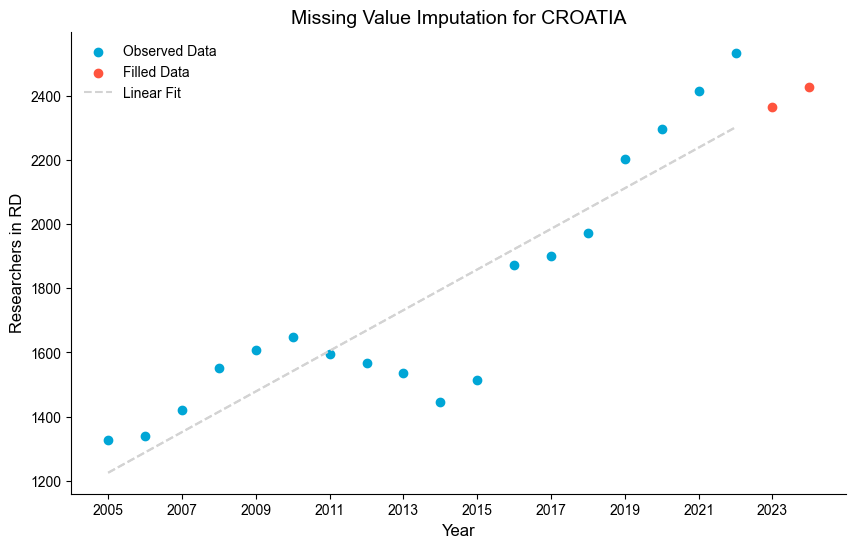

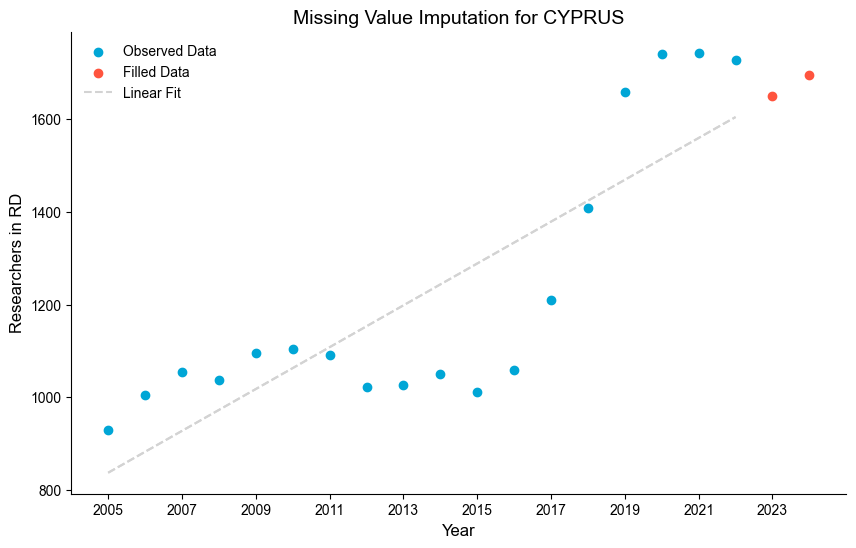

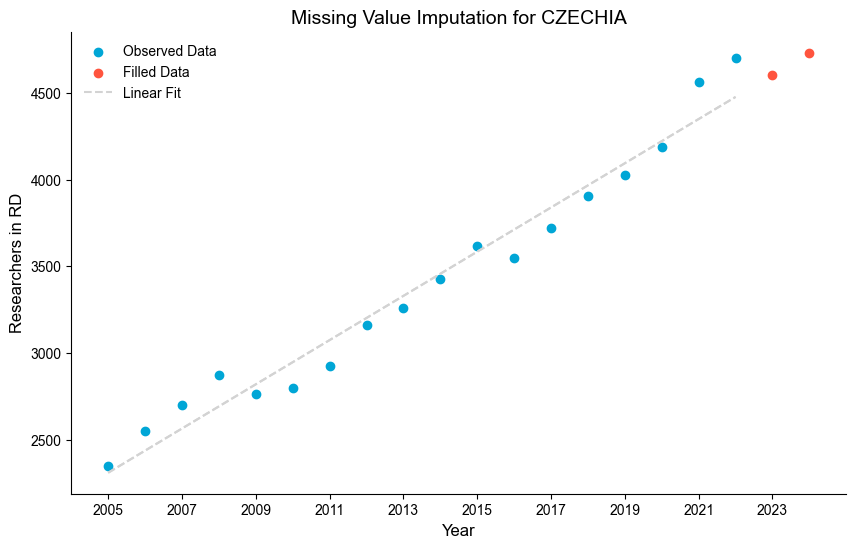

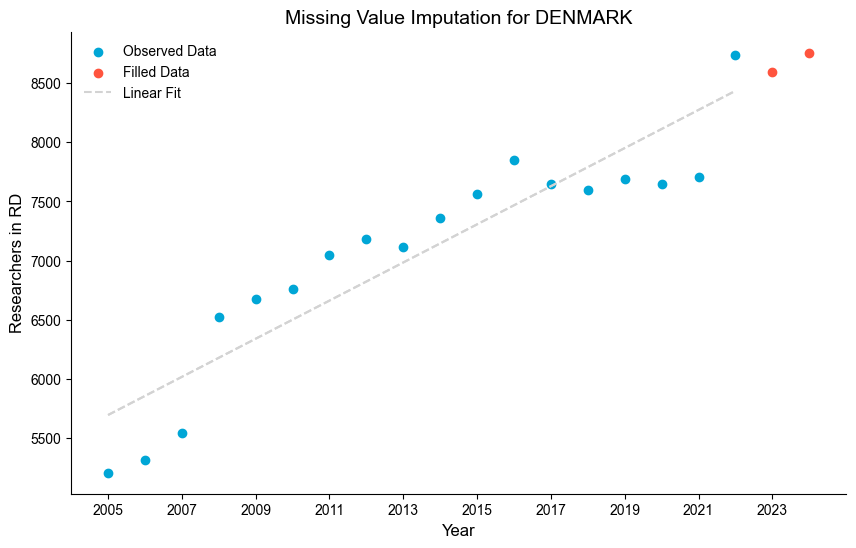

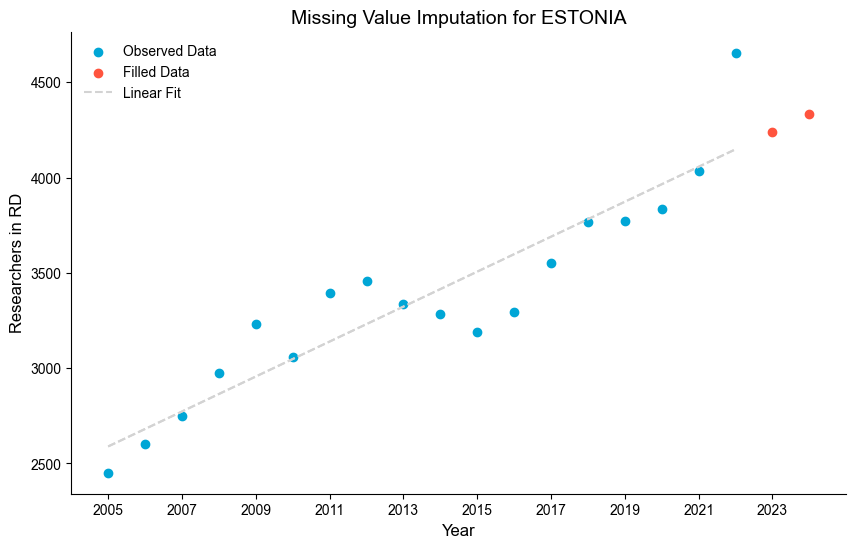

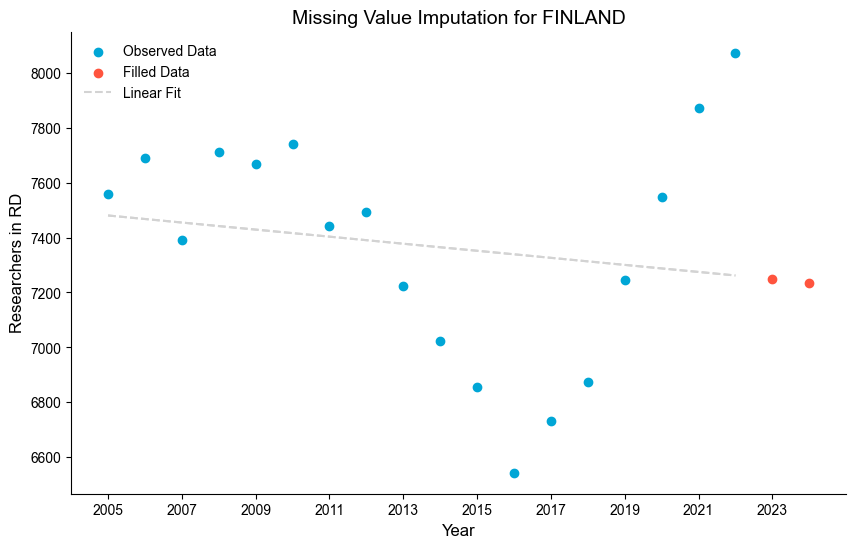

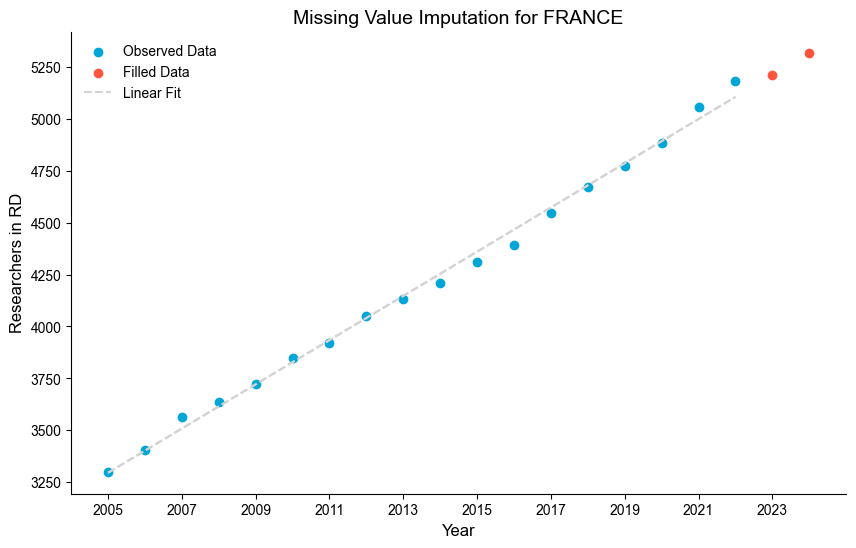

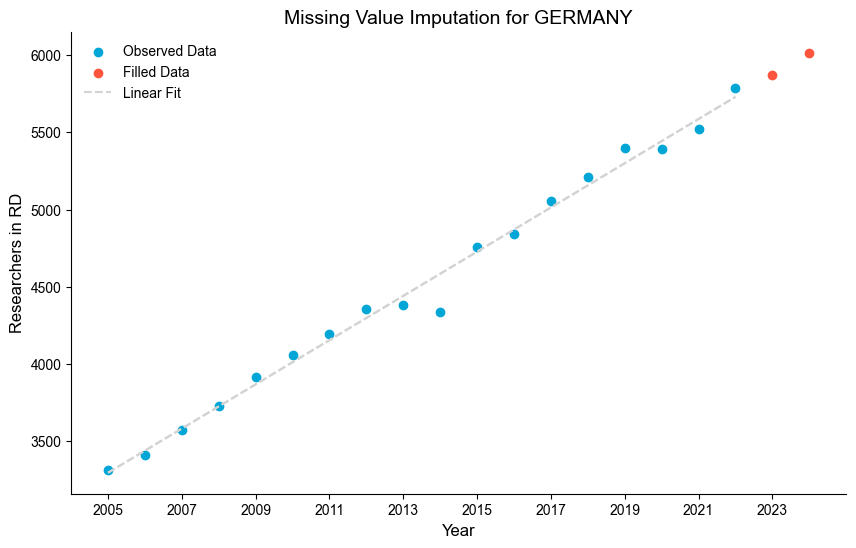

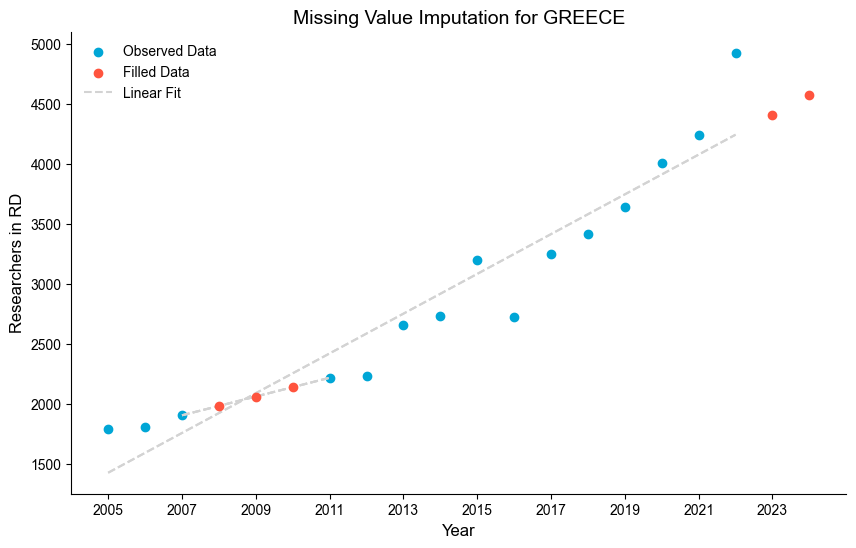

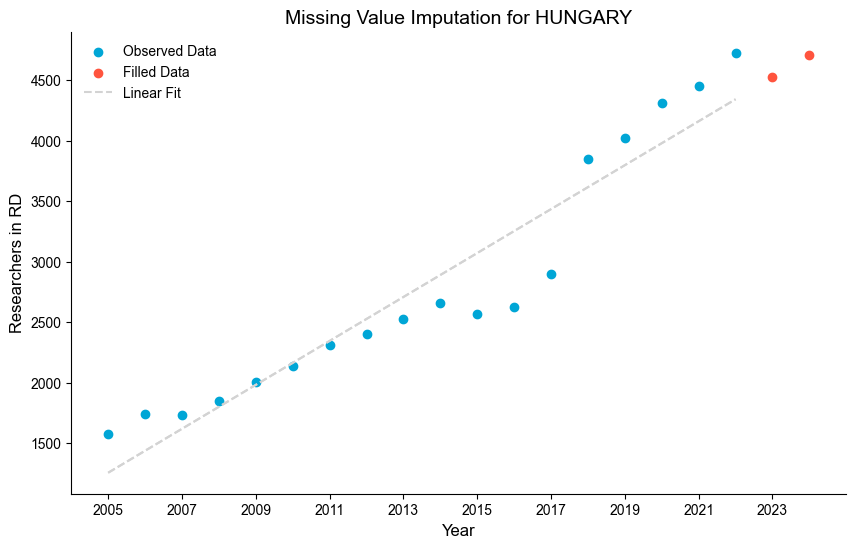

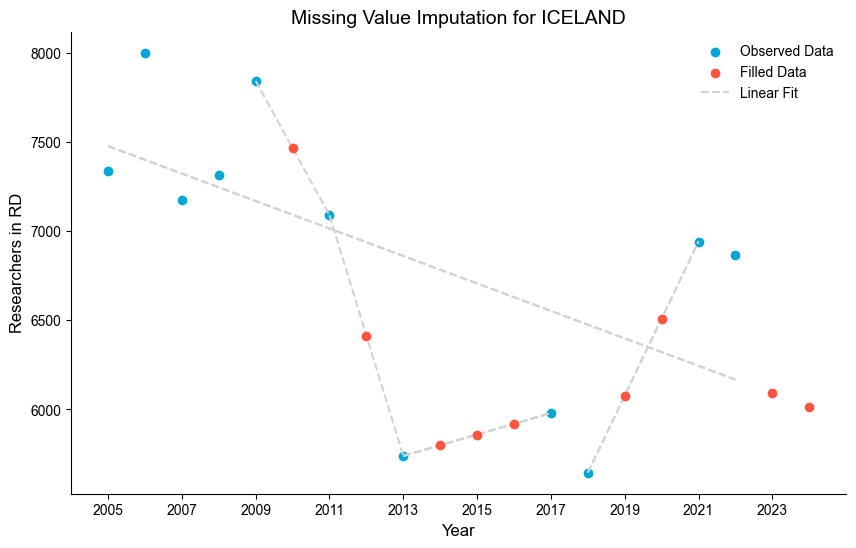

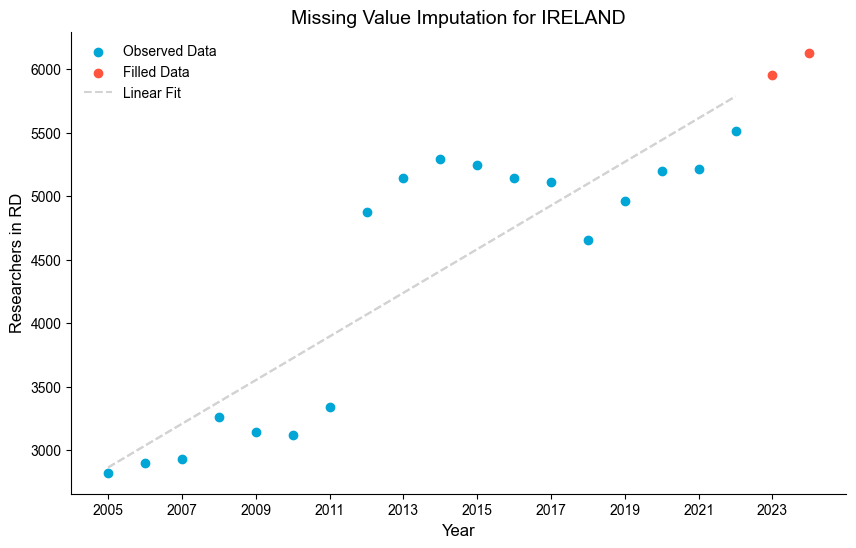

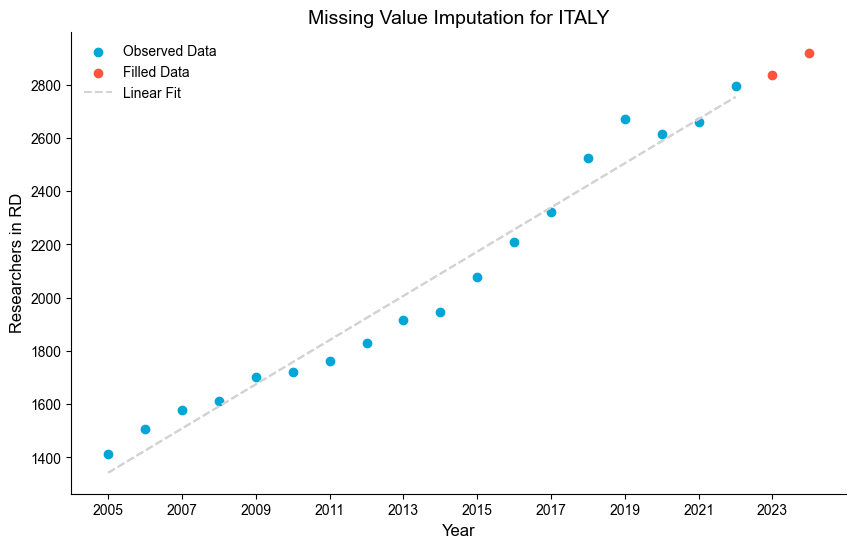

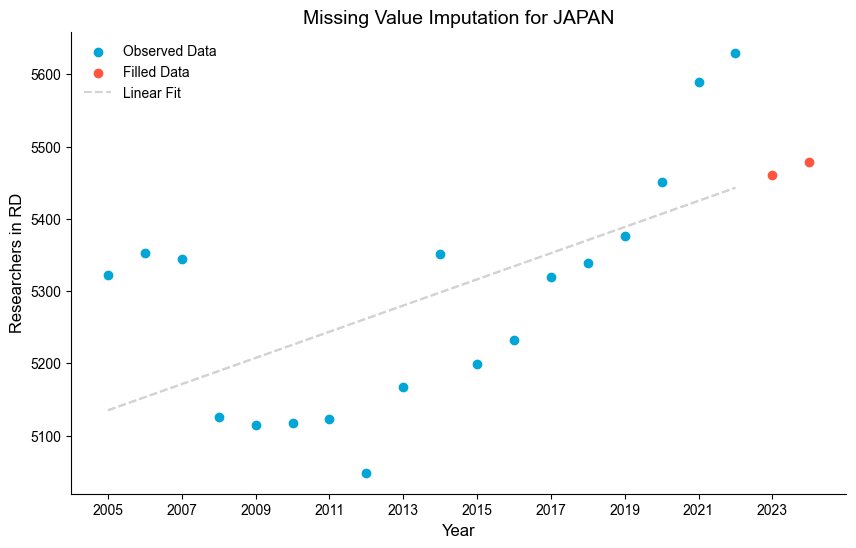

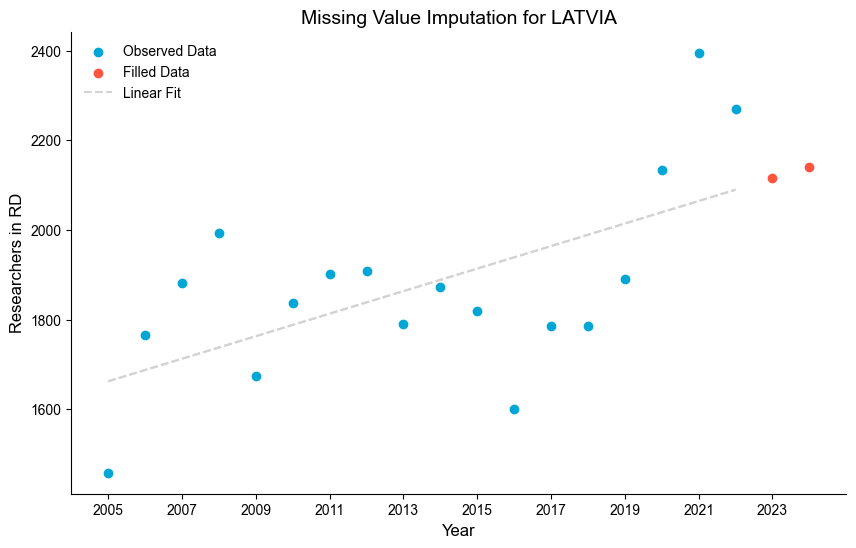

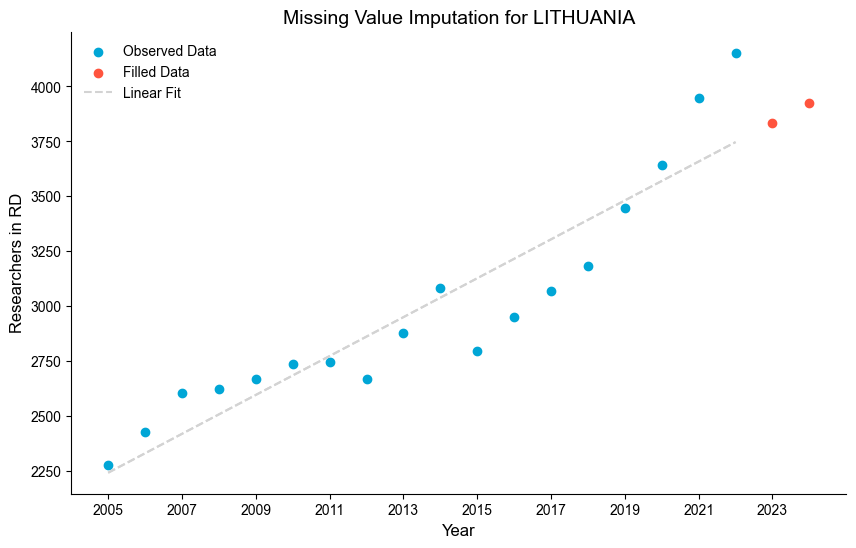

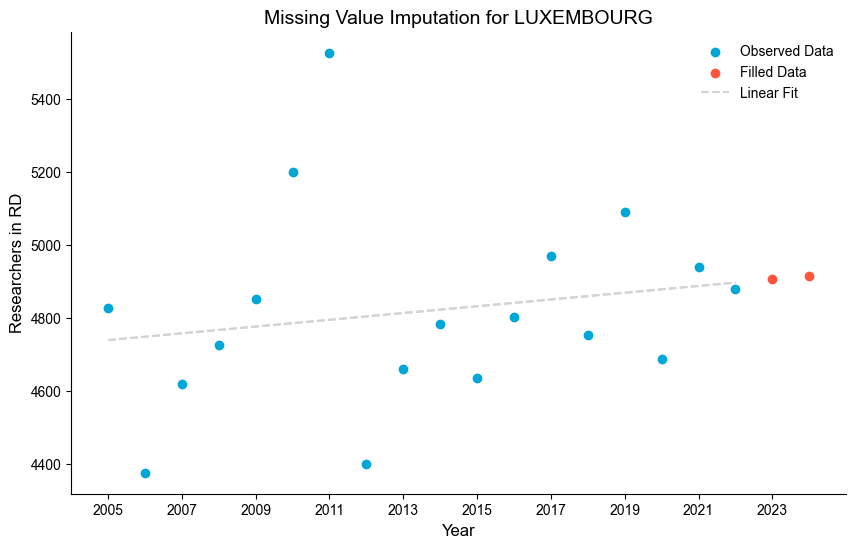

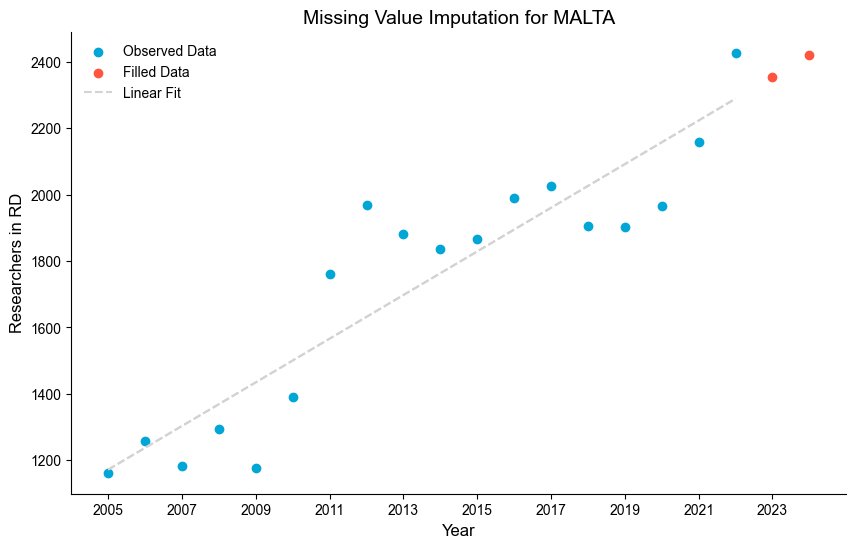

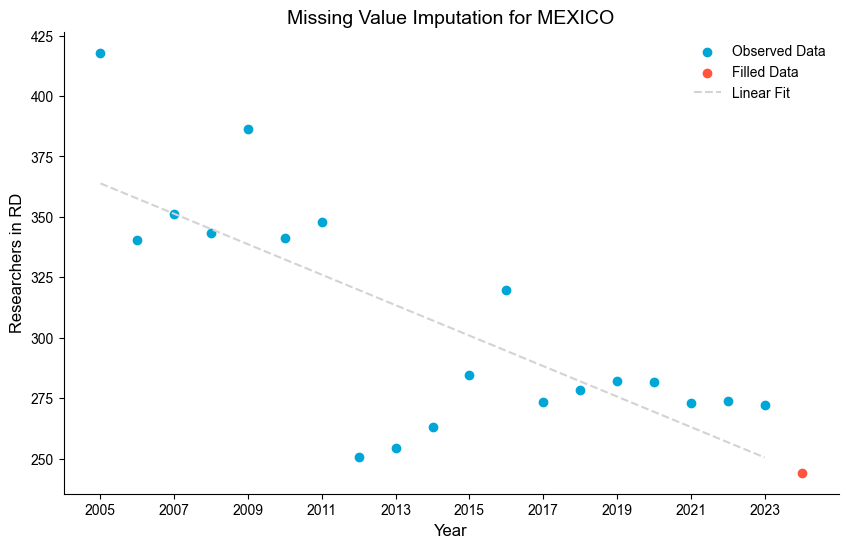

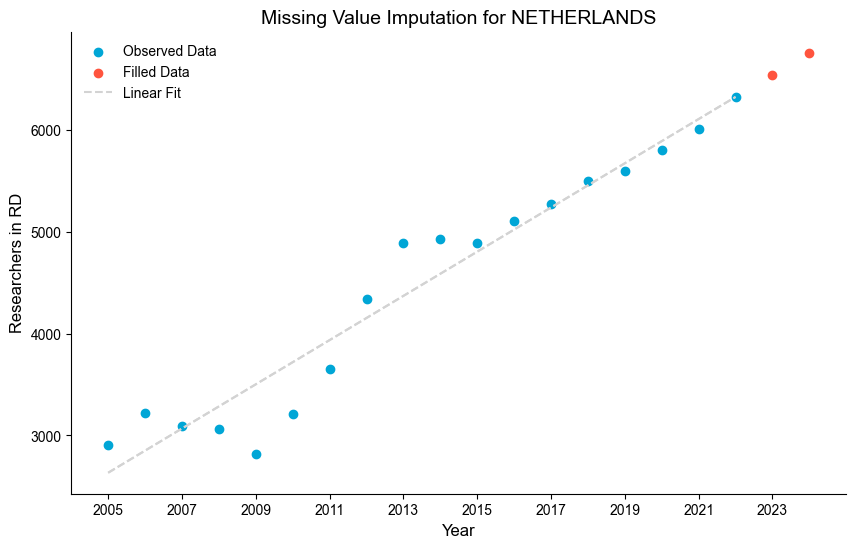

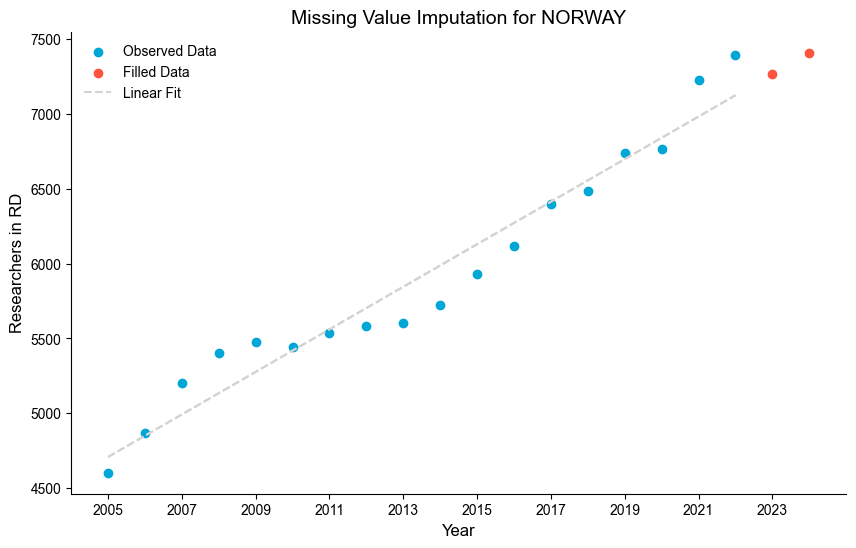

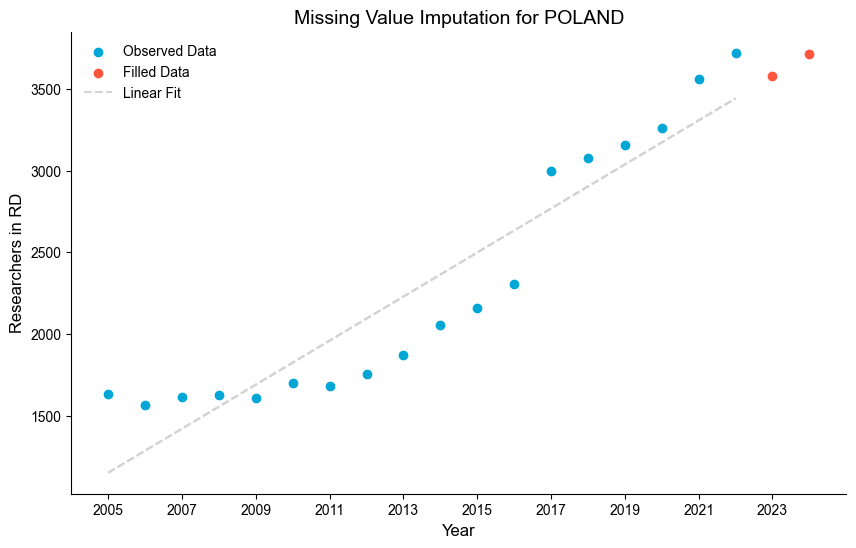

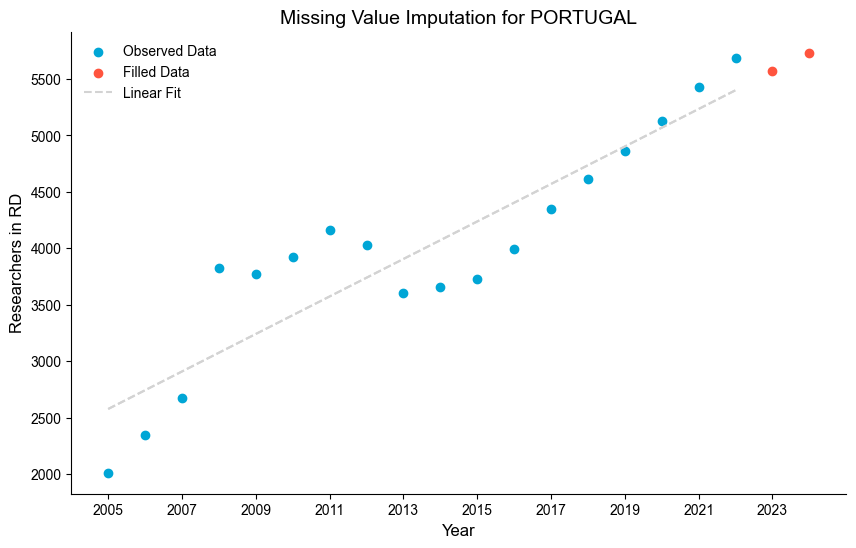

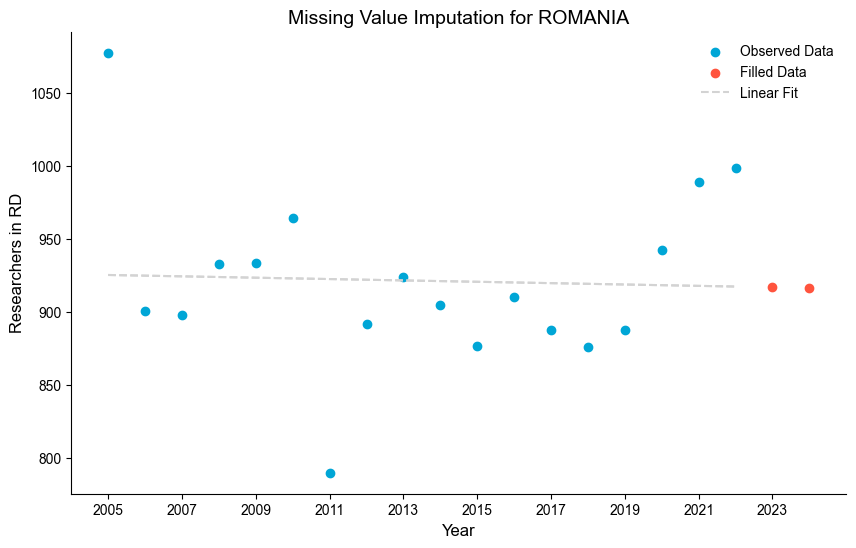

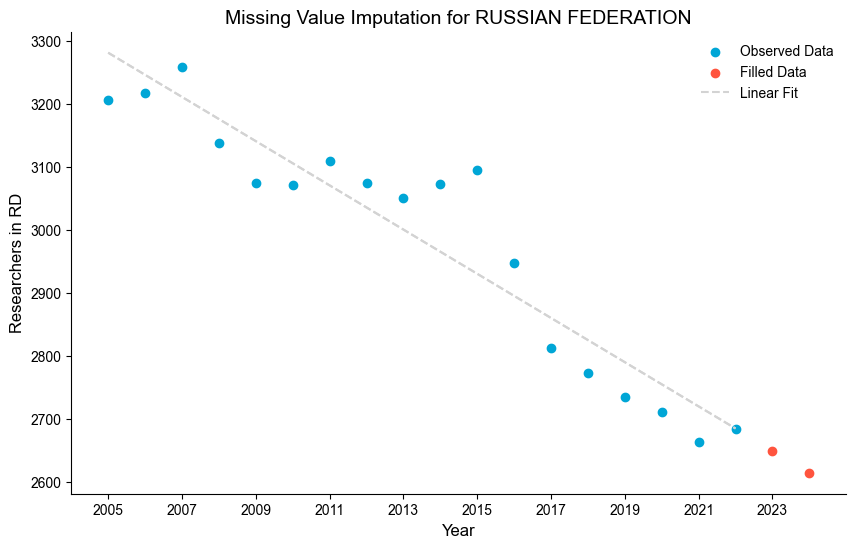

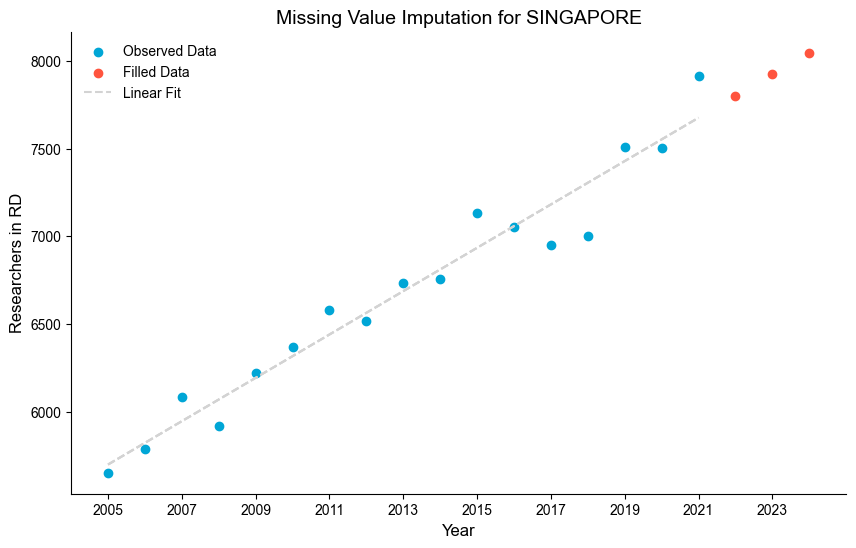

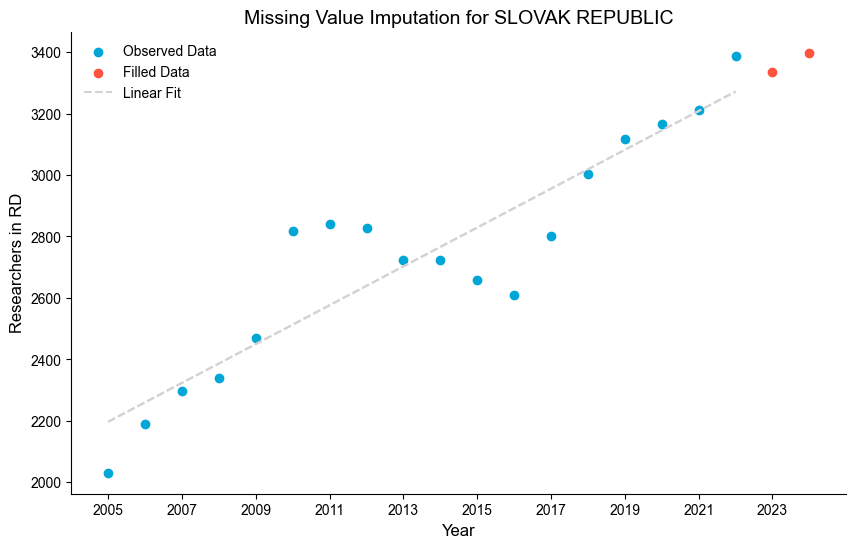

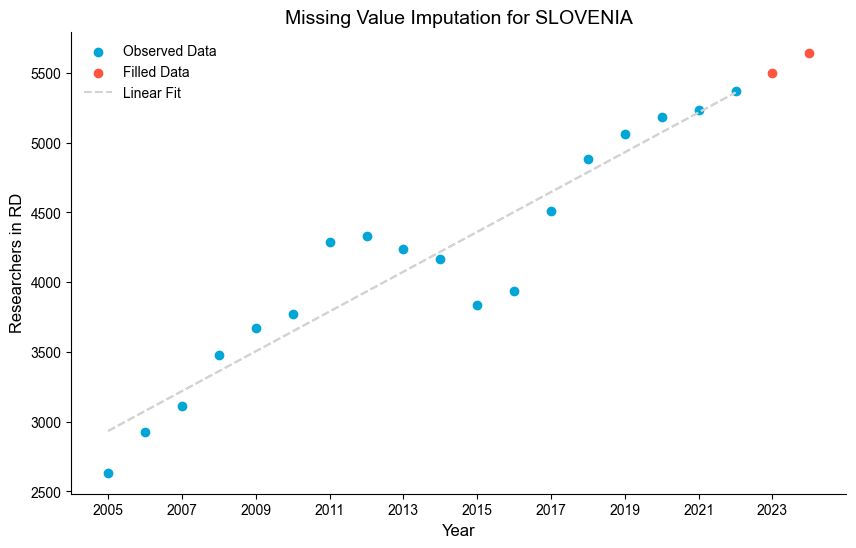

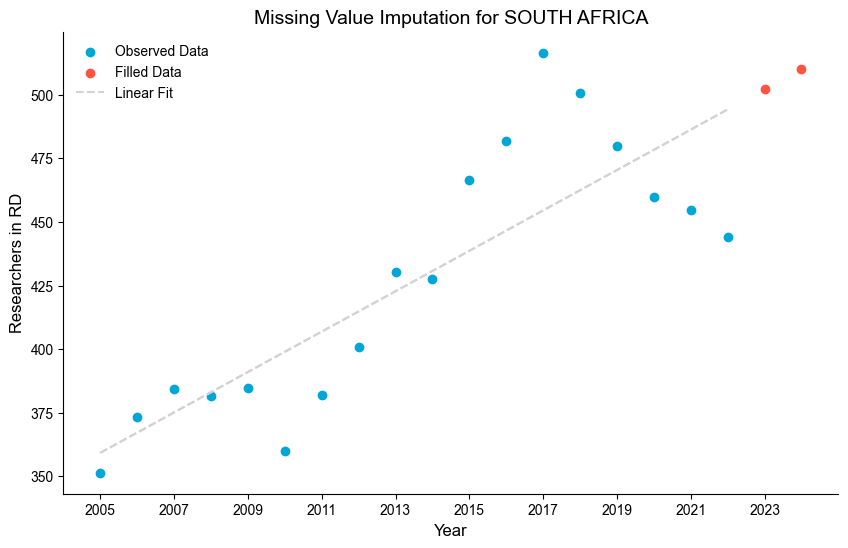

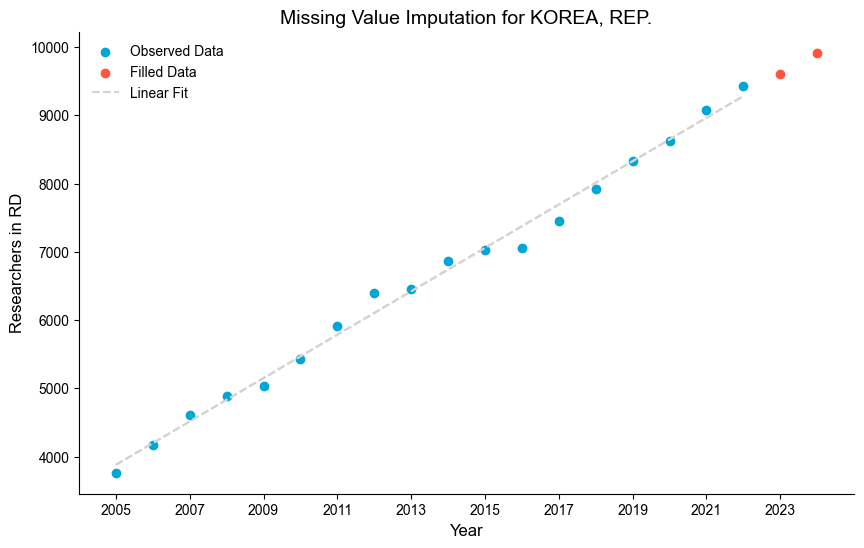

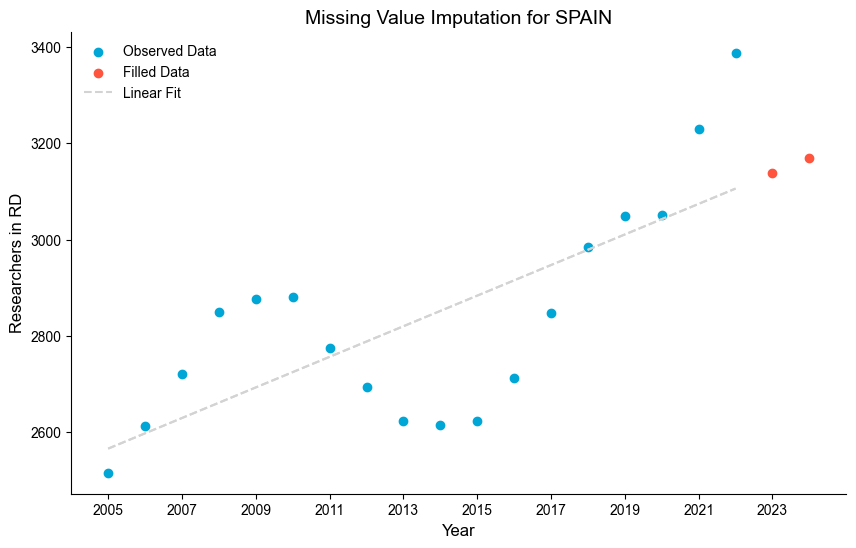

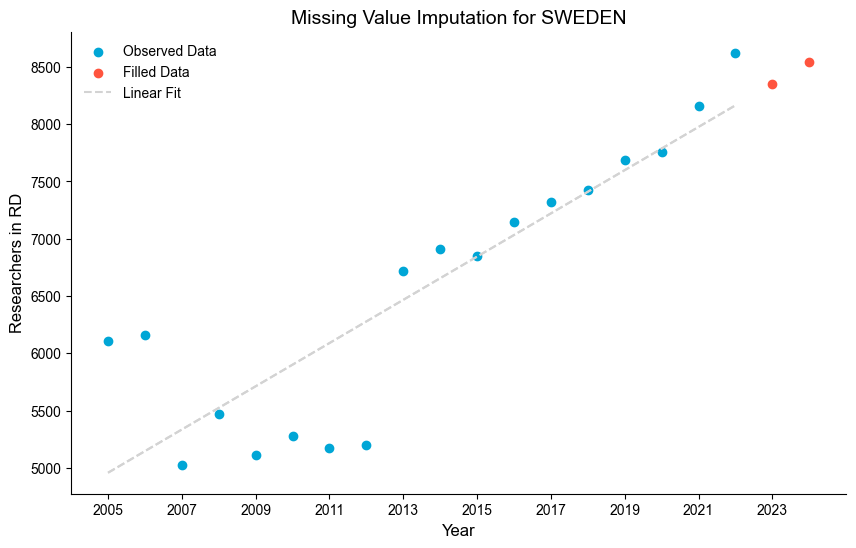

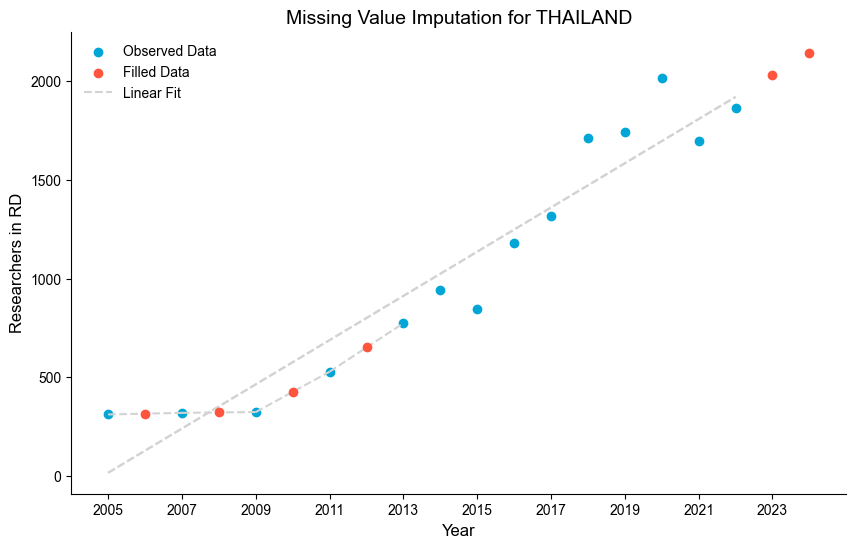

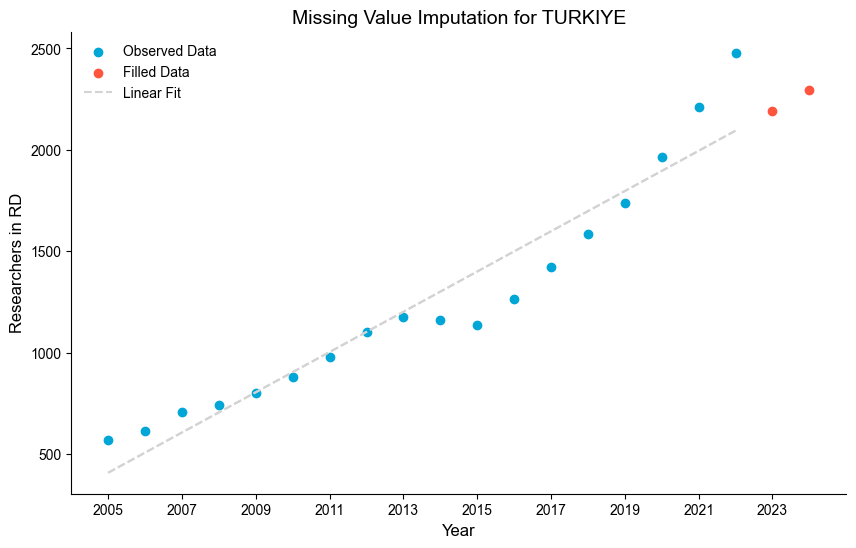

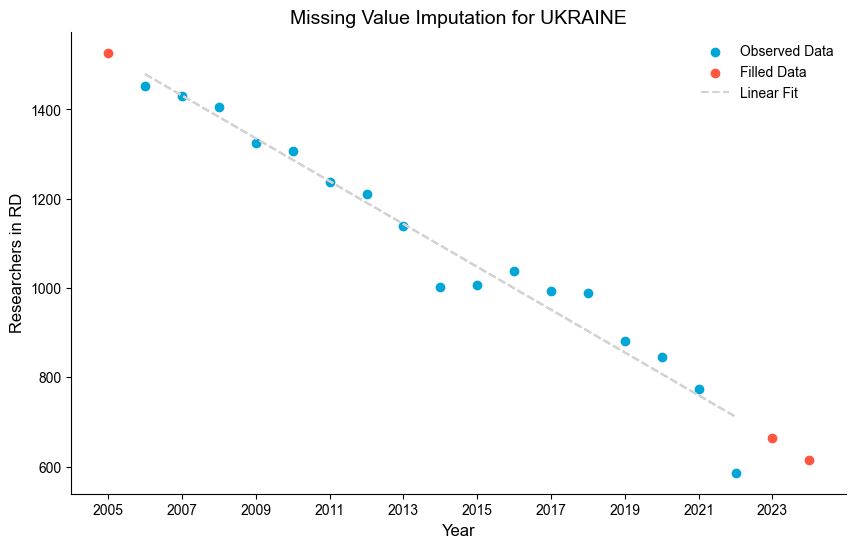

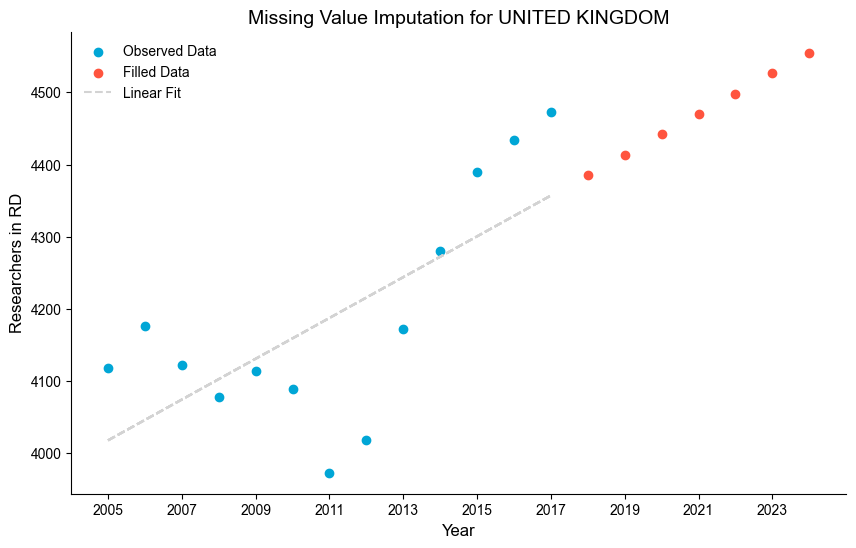

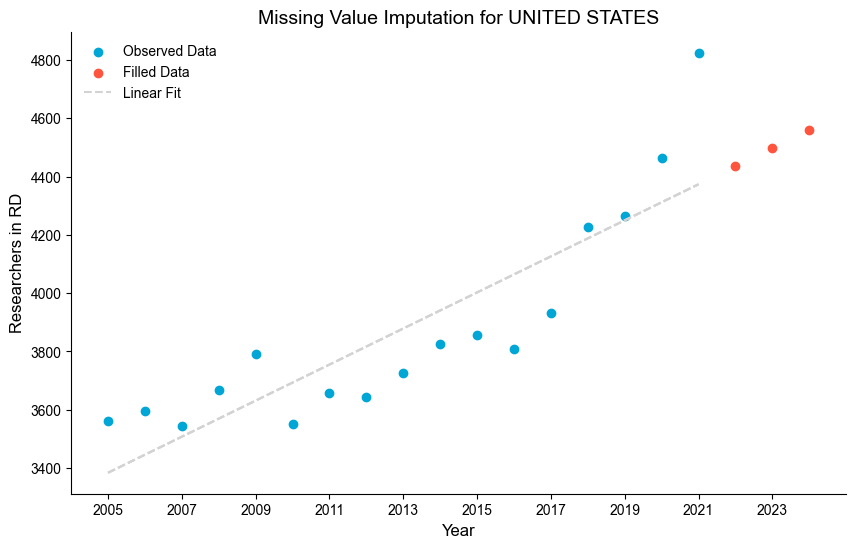

,Country,Year,pub_total,pub_intl,gdp_per_capital,RD,Researchers in RD
0,ARGENTINA,2005,5139,2242,5067.653423,0.42074,816.84120
1,ARGENTINA,2006,5543,2383,5869.380290,0.45216,888.89168
2,ARGENTINA,2007,5947,2596,7185.251551,0.46007,971.29008
3,ARGENTINA,2008,6758,2928,8944.110266,0.47055,1032.67483
4,ARGENTINA,2009,7122,3120,8150.235270,0.58398,1031.64133


In [22]:
fitting_df_researchers = analyze_and_fill_missing_values(fitting_df_RD, 'Researchers in RD')
fitting_df_researchers.head()

In [27]:
# 重命名列
fitting_df_researchers = fitting_df_researchers.rename(columns={'gdp_per_capital': 'gdp_per_capita'})
# 计算国际合作比例
fitting_df_researchers['intl_ratio'] = fitting_df_researchers['pub_intl'] / fitting_df_researchers['pub_total']
fitting_df_researchers


,Country,Year,pub_total,pub_intl,gdp_per_capita,RD,Researchers in RD,intl_ratio
0,ARGENTINA,2005,5139,2242,5067.653423,0.420740,816.841200,0.436272
1,ARGENTINA,2006,5543,2383,5869.380290,0.452160,888.891680,0.429912
2,ARGENTINA,2007,5947,2596,7185.251551,0.460070,971.290080,0.436523
3,ARGENTINA,2008,6758,2928,8944.110266,0.470550,1032.674830,0.433264
4,ARGENTINA,2009,7122,3120,8150.235270,0.583980,1031.641330,0.438079
...,...,...,...,...,...,...,...,...
895,UNITED STATES,2020,504661,219508,64401.507435,3.424670,4464.094950,0.434961
896,UNITED STATES,2021,522515,228087,71307.401728,3.483130,4825.180400,0.436518
897,UNITED STATES,2022,462747,204386,77860.911291,3.586230,4435.672600,0.441680
898,UNITED STATES,2023,426755,189201,82304.620427,3.383009,4497.535613,0.443348


In [29]:
final_completed_dir = "/Users/sunmengge/Dropbox/RUSSIA_UKRAIN_WAR_ALL_CODES/0raw_publiations_process/indicator_clean_data/final_completed.xlsx"
fitting_df_researchers.to_excel(final_completed_dir, index=False)
final_completed_dir2 = "/Users/sunmengge/Dropbox/RUSSIA_UKRAIN_WAR_ALL_CODES/crimes/original_completed.xlsx"
fitting_df_researchers.to_excel(final_completed_dir2, index=False)
final_completed_dir3 = "/Users/sunmengge/Dropbox/RUSSIA_UKRAIN_WAR_ALL_CODES/crimes_2015_2022/original_completed.xlsx"
fitting_df_researchers.to_excel(final_completed_dir3, index=False)
final_completed_dir4 = "/Users/sunmengge/Dropbox/RUSSIA_UKRAIN_WAR_ALL_CODES/crimes_2015_2022/original_completed.xlsx"
fitting_df_researchers.to_excel(final_completed_dir4, index=False)